In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from influxdb import InfluxDBClient

client = InfluxDBClient(
    host= "10.64.44.196",
    port= 8086,
    username = "ilbekas",
    password = "!I[j~gtN25m{",
    database="workloads_IoT"
)

query = "SELECT * FROM workloads"
result = client.query(query)

points = list(result.get_points())

df = pd.DataFrame(points)

df.head()

,time,MB,bandwidth_req_mbps,data_amount_mb,dst_node,duration_s,exec_unit_id,jitter_ms,packet_loss_percent,src_node,throughput_mbps,total_energy_Wh,total_rx_Wh,total_tx_Wh
0,2025-12-23T17:36:09.117197Z,37.597839,2.4,40.0,node03,142.837769,exec_1766511369,1.865,8.1,node06,2.31,0.049112,0.010256,0.038856
1,2025-12-23T17:46:09.289206Z,137.799147,2.4,158.0,node06,570.185862,exec_1766511969,2.394,19.0,node03,1.91,0.168933,0.030614,0.138319
2,2025-12-23T17:46:11.746977Z,118.745684,2.4,138.0,node09,488.978863,exec_1766511971,1.530,19.0,node12,1.93,0.149395,0.027073,0.122322
3,2025-12-23T17:46:12.564614Z,146.549548,2.4,200.0,node10,714.699337,exec_1766511972,2.831,32.0,node11,1.61,0.172310,0.030822,0.141488
4,2025-12-23T17:54:42.095090Z,162.154786,2.4,169.0,node12,581.410376,exec_1766512482,1.439,9.8,node09,2.22,0.242146,0.040616,0.201530


In [3]:
# =========================================================
# CELL 2 — TEMPORAL RECONSTRUCTION & TEMPORAL FEATURES
# =========================================================

import pandas as pd
import numpy as np

# =========================================================
# CREATE TEMPORAL DATAFRAME
# =========================================================

df_temporal = df.copy()

# =========================================================
# 1. TIMESTAMP NORMALIZATION
# =========================================================

print("\n========== TIMESTAMP NORMALIZATION ==========\n")

df_temporal["time"] = pd.to_datetime(
    df_temporal["time"],
    utc=True,
    errors="coerce"
)

print("Timestamp conversion completed.")

# =========================================================
# 2. CHRONOLOGICAL SORTING
# =========================================================

df_temporal = (
    df_temporal
    .sort_values("time")
    .reset_index(drop=True)
)

print("\nDataset sorted chronologically.")

# =========================================================
# 3. END-TIME RECONSTRUCTION
# =========================================================

print("\n========== END-TIME RECONSTRUCTION ==========\n")

df_temporal["end_time"] = (
    df_temporal["time"] +
    pd.to_timedelta(
        df_temporal["duration_s"],
        unit="s"
    )
)

print("End-time reconstruction completed.")

# =========================================================
# 4. TEMPORAL INTEGRITY CHECKS
# =========================================================

print("\n========== TEMPORAL INTEGRITY CHECKS ==========\n")

# missing timestamps
missing_start_times = (
    df_temporal["time"]
    .isna()
    .sum()
)

missing_end_times = (
    df_temporal["end_time"]
    .isna()
    .sum()
)

# invalid durations
non_positive_duration = (
    (df_temporal["duration_s"] <= 0)
    .sum()
)

# impossible intervals
invalid_intervals = (
    (df_temporal["end_time"] < df_temporal["time"])
    .sum()
)

print(f"Missing start timestamps:     {missing_start_times}")
print(f"Missing end timestamps:       {missing_end_times}")
print(f"Non-positive durations:       {non_positive_duration}")
print(f"Invalid temporal intervals:   {invalid_intervals}")

# =========================================================
# 5. TEMPORAL COVERAGE
# =========================================================

print("\n========== TEMPORAL COVERAGE ==========\n")

start_time = df_temporal["time"].min()
end_time = df_temporal["time"].max()

dataset_span_days = (
    (end_time - start_time)
    .total_seconds()
    / (60 * 60 * 24)
)

print(f"Earliest workload:   {start_time}")
print(f"Latest workload:     {end_time}")
print(f"Dataset span:        {dataset_span_days:.2f} days")

# =========================================================
# 6. BASIC TEMPORAL DECOMPOSITION
# =========================================================

print("\n========== TEMPORAL FEATURE ENGINEERING ==========\n")

# ---------------------------------------------------------
# Hour
# ---------------------------------------------------------

df_temporal["hour"] = (
    df_temporal["time"]
    .dt.hour
)

# ---------------------------------------------------------
# Day of week
# Monday = 0
# Sunday = 6
# ---------------------------------------------------------

df_temporal["day_of_week"] = (
    df_temporal["time"]
    .dt.dayofweek
)

# ---------------------------------------------------------
# Weekend indicator
# ---------------------------------------------------------

df_temporal["is_weekend"] = (
    df_temporal["day_of_week"] >= 5
).astype(int)

# ---------------------------------------------------------
# Month
# ---------------------------------------------------------

df_temporal["month"] = (
    
    df_temporal["time"]
    .dt.month
)

# ---------------------------------------------------------
# Calendar date
# ---------------------------------------------------------

df_temporal["workload_date"] = (
    df_temporal["time"]
    .dt.date
)

# =========================================================
# 7. CYCLICAL TEMPORAL ENCODING
# =========================================================

print("\n========== CYCLICAL TIME ENCODING ==========\n")

df_temporal["hour_sin"] = np.sin(
    2 * np.pi *
    df_temporal["hour"] / 24
)

df_temporal["hour_cos"] = np.cos(
    2 * np.pi *
    df_temporal["hour"] / 24
)

print("Cyclical hour encoding completed.")

# =========================================================
# 8. TEMPORAL FEATURE SUMMARY
# =========================================================

print("\n========== TEMPORAL FEATURE SUMMARY ==========\n")

temporal_features = [
    "hour",
    "day_of_week",
    "is_weekend",
    "month",
    "hour_sin",
    "hour_cos"
]

print(
    df_temporal[
        temporal_features
    ].describe()
)

# =========================================================
# 9. SAMPLE PREVIEW
# =========================================================

print("\n========== TEMPORAL DATASET SAMPLE ==========\n")

display(
    df_temporal[[
        "time",
        "end_time",
        "duration_s",
        "hour",
        "day_of_week",
        "is_weekend",
        "hour_sin",
        "hour_cos"
    ]].head()
)

# =========================================================
# 10. FINAL DATAFRAME SHAPE
# =========================================================

print("\n========== FINAL TEMPORAL DATAFRAME ==========\n")

print(f"Rows:    {df_temporal.shape[0]}")
print(f"Columns: {df_temporal.shape[1]}")


========== TIMESTAMP NORMALIZATION ==========

Timestamp conversion completed.

Dataset sorted chronologically.

========== END-TIME RECONSTRUCTION ==========

End-time reconstruction completed.

========== TEMPORAL INTEGRITY CHECKS ==========

Missing start timestamps:     0
Missing end timestamps:       0
Non-positive durations:       0
Invalid temporal intervals:   0

========== TEMPORAL COVERAGE ==========

Earliest workload:   2025-12-23 17:36:09.117197+00:00
Latest workload:     2026-06-28 09:08:57.064028+00:00
Dataset span:        186.65 days

========== TEMPORAL FEATURE ENGINEERING ==========


========== CYCLICAL TIME ENCODING ==========

Cyclical hour encoding completed.

========== TEMPORAL FEATURE SUMMARY ==========

               hour   day_of_week    is_weekend         month      hour_sin  \
count  37353.000000  37353.000000  37353.000000  37353.000000  37353.000000   
mean      11.739994      3.481702      0.349021      3.437180     -0.024853   
std        6.660057    

,time,end_time,duration_s,hour,day_of_week,is_weekend,hour_sin,hour_cos
0,2025-12-23 17:36:09.117197+00:00,2025-12-23 17:38:31.954966+00:00,142.837769,17,1,0,-0.965926,-0.258819
1,2025-12-23 17:46:09.289206+00:00,2025-12-23 17:55:39.475068+00:00,570.185862,17,1,0,-0.965926,-0.258819
2,2025-12-23 17:46:11.746977+00:00,2025-12-23 17:54:20.725840+00:00,488.978863,17,1,0,-0.965926,-0.258819
3,2025-12-23 17:46:12.564614+00:00,2025-12-23 17:58:07.263951+00:00,714.699337,17,1,0,-0.965926,-0.258819
4,2025-12-23 17:54:42.095090+00:00,2025-12-23 18:04:23.505466+00:00,581.410376,17,1,0,-0.965926,-0.258819



========== FINAL TEMPORAL DATAFRAME ==========

Rows:    37353
Columns: 22


In [4]:
df.tail()

,time,MB,bandwidth_req_mbps,data_amount_mb,dst_node,duration_s,exec_unit_id,jitter_ms,packet_loss_percent,src_node,throughput_mbps,total_energy_Wh,total_rx_Wh,total_tx_Wh
37348,2026-06-28T09:03:12.965862Z,27.513747,1.48,64.433594,node07,550.993988,exec_dced7a56bcf14448b58de9fdee996c4d,7.814,56.0,node08,0.4340,0.044132,0.000000,0.044132
37349,2026-06-28T09:04:28.987569Z,41.519855,2.02,82.177734,node06,1016.112963,exec_6ee4b095a6d047c2bf443d593ee0097b,86.187,87.0,node03,0.0840,0.141460,0.009233,0.132227
37350,2026-06-28T09:04:58.612410Z,49.498284,2.24,41.679688,node10,172.494123,exec_77f61bec513a456cb8253a6b730703d2,7.209,53.0,node11,0.9800,0.047136,0.012036,0.035100
37351,2026-06-28T09:06:37.138512Z,107.002688,1.94,92.998047,node10,406.314426,exec_cfc943e9fea14b6f834617ea8f126133,2.305,9.0,node11,1.7600,0.095624,0.025543,0.070081
37352,2026-06-28T09:08:57.064028Z,31.858235,0.99,57.470703,node06,699.001041,exec_8dac48b4ce8644ad90a284d1e46f1a3a,172.290,87.0,node03,0.0873,0.100863,0.007085,0.093778


In [5]:
df = df_temporal.copy()

In [6]:
# =========================================================
# CELL 3 — GLOBAL CONCURRENCY MODELLING (ASYMMETRIC MATRIX)
# =========================================================
import numpy as np
import pandas as pd

INTERFERENCE_MATRIX = {
    (("link1", "downlink"), ("link2", "downlink")): {
        "link1": 0.875,
        "link2": 0.875
    },
    (("link1", "downlink"), ("link2", "uplink")): {
        "link1": 0.0417,
        "link2": 0.9167
    },
    (("link1", "downlink"), ("link3", "downlink")): {
        "link1": 0.5,
        "link3": 0.5
    },
    (("link1", "downlink"), ("link3", "uplink")): {
        "link1": 0.4583,
        "link3": 0.5417
    },
    (("link1", "downlink"), ("link4", "downlink")): {
        "link1": 0.0,
        "link4": 0.0
    },
    (("link1", "downlink"), ("link4", "uplink")): {
        "link1": 0.0,
        "link4": 0.0
    },
    (("link1", "downlink"), ("link5", "downlink")): {
        "link1": 0.0,
        "link5": 0.0
    },
    (("link1", "downlink"), ("link5", "uplink")): {
        "link1": 0.0,
        "link5": 0.0
    },
    (("link1", "downlink"), ("link6", "downlink")): {
        "link1": 0.75,
        "link6": 0.875
    },
    (("link1", "downlink"), ("link6", "uplink")): {
        "link1": 0.5833,
        "link6": 0.3333
    },
    (("link1", "uplink"), ("link2", "downlink")): {
        "link1": 0.9583,
        "link2": 0.75
    },
    (("link1", "uplink"), ("link2", "uplink")): {
        "link1": 0.8958,
        "link2": 0.7917
    },
    (("link1", "uplink"), ("link3", "downlink")): {
        "link1": 0.75,
        "link3": 0.375
    },
    (("link1", "uplink"), ("link3", "uplink")): {
        "link1": 0.75,
        "link3": 0.375
    },
    (("link1", "uplink"), ("link4", "downlink")): {
        "link1": 0.0833,
        "link4": 0.0
    },
    (("link1", "uplink"), ("link4", "uplink")): {
        "link1": 0.0833,
        "link4": 0.0
    },
    (("link1", "uplink"), ("link5", "downlink")): {
        "link1": 0.0833,
        "link5": 0.0
    },
    (("link1", "uplink"), ("link5", "uplink")): {
        "link1": 0.0833,
        "link5": 0.0
    },
    (("link1", "uplink"), ("link6", "downlink")): {
        "link1": 0.4167,
        "link6": 0.75
    },
    (("link1", "uplink"), ("link6", "uplink")): {
        "link1": 0.625,
        "link6": 0.2917
    },
    (("link2", "downlink"), ("link3", "downlink")): {
        "link2": 0.7917,
        "link3": 0.4083
    },
    (("link2", "downlink"), ("link3", "uplink")): {
        "link2": 0.7083,
        "link3": 0.4583
    },
    (("link2", "downlink"), ("link4", "downlink")): {
        "link2": 0.3333,
        "link4": 0.2917
    },
    (("link2", "downlink"), ("link4", "uplink")): {
        "link2": 0.4375,
        "link4": 0.7917
    },
    (("link2", "downlink"), ("link5", "downlink")): {
        "link2": 0.2708,
        "link5": 0.0
    },
    (("link2", "downlink"), ("link5", "uplink")): {
        "link2": 0.2708,
        "link5": 0.0
    },
    (("link2", "downlink"), ("link6", "downlink")): {
        "link2": 0.25,
        "link6": 0.0
    },
    (("link2", "downlink"), ("link6", "uplink")): {
        "link2": 0.4792,
        "link6": 0.0
    },
    (("link2", "uplink"), ("link3", "downlink")): {
        "link2": 0.8333,
        "link3": 0.3333
    },
    (("link2", "uplink"), ("link3", "uplink")): {
        "link2": 0.5,
        "link3": 0.6667
    },
    (("link2", "uplink"), ("link4", "downlink")): {
        "link2": 0.5833,
        "link4": 0.4167
    },
    (("link2", "uplink"), ("link4", "uplink")): {
        "link2": 0.625,
        "link4": 0.5
    },
    (("link2", "uplink"), ("link5", "downlink")): {
        "link2": 0.375,
        "link5": 0.0
    },
    (("link2", "uplink"), ("link5", "uplink")): {
        "link2": 0.4583,
        "link5": 0.0
    },
    (("link2", "uplink"), ("link6", "downlink")): {
        "link2": 0.75,
        "link6": 0.0
    },
    (("link2", "uplink"), ("link6", "uplink")): {
        "link2": 0.6667,
        "link6": 0.0833
    },
    (("link3", "downlink"), ("link4", "downlink")): {
        "link3": 0.0,
        "link4": 0.0
    },
    (("link3", "downlink"), ("link4", "uplink")): {
        "link3": 0.0417,
        "link4": 0.0417
    },
    (("link3", "downlink"), ("link5", "downlink")): {
        "link3": 0.0,
        "link5": 0.0
    },
    (("link3", "downlink"), ("link5", "uplink")): {
        "link3": 0.0,
        "link5": 0.0
    },
    (("link3", "downlink"), ("link6", "downlink")): {
        "link3": 0.1667,
        "link6": 0.0
    },
    (("link3", "downlink"), ("link6", "uplink")): {
        "link3": 0.25,
        "link6": 0.0
    },
    (("link3", "uplink"), ("link4", "downlink")): {
        "link3": 0.1667,
        "link4": 0.0
    },
    (("link3", "uplink"), ("link4", "uplink")): {
        "link3": 0.375,
        "link4": 0.0
    },
    (("link3", "uplink"), ("link5", "downlink")): {
        "link3": 0.2083,
        "link5": 0.0
    },
    (("link3", "uplink"), ("link5", "uplink")): {
        "link3": 0.0,
        "link5": 0.0
    },
    (("link3", "uplink"), ("link6", "downlink")): {
        "link3": 0.2083,
        "link6": 0.0
    },
    (("link3", "uplink"), ("link6", "uplink")): {
        "link3": 0.125,
        "link6": 0.0
    },
    (("link4", "downlink"), ("link5", "downlink")): {
        "link4": 0.6667,
        "link5": 0.3333
    },
    (("link4", "downlink"), ("link5", "uplink")): {
        "link4": 0.7083,
        "link5": 0.5333
    },
    (("link4", "downlink"), ("link6", "downlink")): {
        "link4": 0.0,
        "link6": 0.0
    },
    (("link4", "downlink"), ("link6", "uplink")): {
        "link4": 0.4583,
        "link6": 0.4583
    },
    (("link4", "uplink"), ("link5", "downlink")): {
        "link4": 0.3333,
        "link5": 0.5833
    },
    (("link4", "uplink"), ("link5", "uplink")): {
        "link4": 0.0,
        "link5": 0.0
    },
    (("link4", "uplink"), ("link6", "downlink")): {
        "link4": 0.0,
        "link6": 0.0
    },
    (("link4", "uplink"), ("link6", "uplink")): {
        "link4": 0.1667,
        "link6": 0.0833
    },
    (("link5", "downlink"), ("link6", "downlink")): {
        "link5": 0.2083,
        "link6": 0.125
    },
    (("link5", "downlink"), ("link6", "uplink")): {
        "link5": 0.0,
        "link6": 0.0
    },
    (("link5", "uplink"), ("link6", "downlink")): {
        "link5": 0.2083,
        "link6": 0.0833
    },
    (("link5", "uplink"), ("link6", "uplink")): {
        "link5": 0.0,
        "link6": 0.0
    },
}

def get_asymmetric_weight(link_candidate, dir_candidate, link_active, dir_active):
    """ Fast matrix extractor isolating the candidate's exact penalty factor """
    if link_candidate == link_active:
        return 0.0  # Safe fallback (same link handled via local rules or skipped)
        
    key_1 = ((link_candidate, dir_candidate), (link_active, dir_active))
    key_2 = ((link_active, dir_active), (link_candidate, dir_candidate))
    
    if key_1 in INTERFERENCE_MATRIX:
        return INTERFERENCE_MATRIX[key_1].get(link_candidate, 0.1)
    if key_2 in INTERFERENCE_MATRIX:
        return INTERFERENCE_MATRIX[key_2].get(link_candidate, 0.1)
    return 0.1  # Conservative fallback factor

# ---------------------------------------------------------
# 2. LINK STRUTURAL MAP DICTIONARY
# ---------------------------------------------------------
LINK_MAP = {
    ("node01", "node05"): "link1", ("node03", "node06"): "link2",
    ("node02", "node04"): "link3", ("node07", "node08"): "link4",
    ("node09", "node12"): "link5", ("node10", "node11"): "link6",

    ("node05", "node01"): "link1", ("node06", "node03"): "link2",
    ("node04", "node02"): "link3", ("node08", "node07"): "link4",
    ("node12", "node09"): "link5", ("node11", "node10"): "link6",
}

# Explicitly identify downlinks from the original description mappings
DOWNLINK_PAIRS = {
    ("node01", "node05"), ("node03", "node06"), ("node02", "node04"),
    ("node07", "node08"), ("node09", "node12"), ("node10", "node11")
}

# ---------------------------------------------------------
# 3. SAFETY SORT AND STATE FEATURE EXTRACTION
# ---------------------------------------------------------
df = df.sort_values("time").reset_index(drop=True)
n = len(df)

# Vectorized setup for rapid sweep executions
start_times_raw = df["time"].values
end_times_raw = df["end_time"].values
durations = df["duration_s"].values

# Convert NumPy datetime64 objects directly to epoch float arrays for high-speed arithmetic
start_times = start_times_raw.astype("datetime64[s]").astype(float)
end_times = end_times_raw.astype("datetime64[s]").astype(float)

# Pre-resolve topologies for each entry to completely avoid string lookups inside the loop
link_ids = []
directions = []

for idx, row in df.iterrows():
    pair = (row["src_node"], row["dst_node"])
    link = LINK_MAP.get(pair, "link_unknown")
    direction = "downlink" if pair in DOWNLINK_PAIRS else "uplink"
    link_ids.append(link)
    directions.append(direction)

# ---------------------------------------------------------
# 4. HIGH-SPEED EVENT GENERATOR
# ---------------------------------------------------------
events = []
for i in range(n):
    events.append((start_times[i], "start", i))
    events.append((end_times[i], "end", i))

# Sort events strictly chronologically
events.sort(key=lambda x: x[0])

# Output array allocations
overlap_accumulator = np.zeros(n)
effective_concurrency = np.zeros(n)

# Tracking states
active_indices = set()
previous_time = events[0][0] if n > 0 else 0.0

# ---------------------------------------------------------
# 5. LINEAR SWEEP INTERVAL INTERFERENCE PROCESSING
# ---------------------------------------------------------
for current_time, event_type, task_idx in events:
    duration_delta = current_time - previous_time

    # Evaluate the interval only if there is a positive delta and items are running
    if duration_delta > 0.0 and len(active_indices) > 1:
        active_list = list(active_indices)
        
        # Calculate cross-interference impact factors for every active pair within the delta
        for i in active_list:
            link_i = link_ids[i]
            dir_i = directions[i]
            
            total_interference_rate = 0.0
            for j in active_list:
                if i == j:
                    continue
                
                # Dynamic asymmetric lookup: Task i is Victim, Task j is Aggressor
                weight_i = get_asymmetric_weight(link_i, dir_i, link_ids[j], directions[j])
                total_interference_rate += weight_i
            
            # Accumulate weight-proportional exposure units directly
            overlap_accumulator[i] += duration_delta * total_interference_rate

    # Commit state transitions
    if event_type == "start":
        active_indices.add(task_idx)
    else:
        active_indices.remove(task_idx)
        # Compute exact normalized score when the job lifetime ends
        effective_concurrency[task_idx] = overlap_accumulator[task_idx] / max(durations[task_idx], 1e-6)

    previous_time = current_time

# ---------------------------------------------------------
# 6. ATTACH FEATURES TO DATAFRAME & REPORT SUMMARY
# ---------------------------------------------------------
df["effective_concurrency"] = effective_concurrency

print("\n========== CONCURRENCY FEATURE SUMMARY ==========\n")
print(df[["effective_concurrency"]].describe())
print("\nMax effective concurrency observed:", df["effective_concurrency"].max())
print("=================================================")


========== CONCURRENCY FEATURE SUMMARY ==========

       effective_concurrency
count           37353.000000
mean                0.651558
std                 0.713736
min                 0.000000
25%                 0.048632
50%                 0.431447
75%                 1.062556
max                22.524010

Max effective concurrency observed: 22.524009594202088


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# FIXED LINK MAPPING LAYER
# =========================================================

# Fixed the "node012" typo to "node12" so it matches your actual data perfectly
LINK_MAP = {
    ("node01", "node05"): "link1",
    ("node03", "node06"): "link2",
    ("node02", "node04"): "link3",
    ("node07", "node08"): "link4",
    ("node09", "node12"): "link5",
    ("node10", "node11"): "link6",

    ("node05", "node01"): "link1",
    ("node06", "node03"): "link2",
    ("node04", "node02"): "link3",
    ("node08", "node07"): "link4",
    ("node12", "node09"): "link5", # <-- Fixed typo here from node012 to node12
    ("node11", "node10"): "link6",
}

def get_link_id(row):
    # Sort them to keep it bidirectional
    pair = tuple(sorted([row["src_node"], row["dst_node"]]))
    
    link_str = LINK_MAP.get(pair, "unknown")
    
    if link_str != "unknown":
        return int(link_str.replace("link", ""))
    
    return np.nan # Use NaN instead of a string so it doesn't break integer conversion

# Initialize df_clean directly from df
df_clean = df.copy()

# Apply the mapping mapping function
df_clean["link_id"] = df_clean.apply(get_link_id, axis=1)

# Drop any unmapped/unknown links safely before turning it into an integer feature
df_clean = df_clean.dropna(subset=["link_id"])
df_clean["link_id"] = df_clean["link_id"].astype(int)


# =========================================================
# 0. CLEANING LAYER (CRITICAL FIX)
# =========================================================

# Remove failed / invalid workloads
df_clean = df_clean[
    (df_clean["throughput_mbps"] > 0) &
    (df_clean["data_amount_mb"] > 0) &
    (df_clean["bandwidth_req_mbps"] > 0) &
    (df_clean["total_energy_Wh"] > 0)
].copy()

df_clean = df_clean.reset_index(drop=True)

# Remove extreme outliers (robust analysis)
q_low = df_clean["throughput_mbps"].quantile(0.01)
q_high = df_clean["throughput_mbps"].quantile(0.99)

df_clean = df_clean[
    (df_clean["throughput_mbps"] >= q_low) &
    (df_clean["throughput_mbps"] <= q_high)
]


# =========================================================
# 1. ROBUST NORMALIZED METRICS
# =========================================================

df_clean["throughput_efficiency"] = (
    df_clean["throughput_mbps"] /
    (df_clean["bandwidth_req_mbps"] + 1e-6)
)

df_clean["energy_per_mb"] = (
    df_clean["total_energy_Wh"] /
    (df_clean["data_amount_mb"] + 1e-6)
)

df_clean["energy_efficiency"] = (
    df_clean["data_amount_mb"] /
    (df_clean["total_energy_Wh"] + 1e-6)
)


# =========================================================
# 2. CONDITIONED LINK STATISTICS (KeyError Resolved)
# =========================================================

link_stats = df_clean.groupby("link_id").agg({
    "throughput_efficiency": ["mean", "std"],
    "energy_per_mb": ["mean", "std"],
    "energy_efficiency": ["mean", "std"],
    "effective_concurrency": "mean"
})

link_stats.columns = [
    "_".join(col).strip() for col in link_stats.columns
]

link_stats = link_stats.reset_index()

print("Success! Data grouped by link_id without errors.")
print(link_stats.head())

Success! Data grouped by link_id without errors.
   link_id  throughput_efficiency_mean  throughput_efficiency_std  \
0        1                    0.633168                   0.294432   
1        2                    0.672503                   0.288961   
2        3                    0.592399                   0.268899   
3        4                    0.729813                   0.267217   
4        5                    0.882433                   0.210187   

   energy_per_mb_mean  energy_per_mb_std  energy_efficiency_mean  \
0            0.000820           0.000350             1419.634432   
1            0.001094           0.000430             1049.635344   
2            0.000952           0.006241             1371.998041   
3            0.001333           0.000419              813.334817   
4            0.001362           0.000369              791.766524   

   energy_efficiency_std  effective_concurrency_mean  
0             577.622498                    0.902530  
1             430

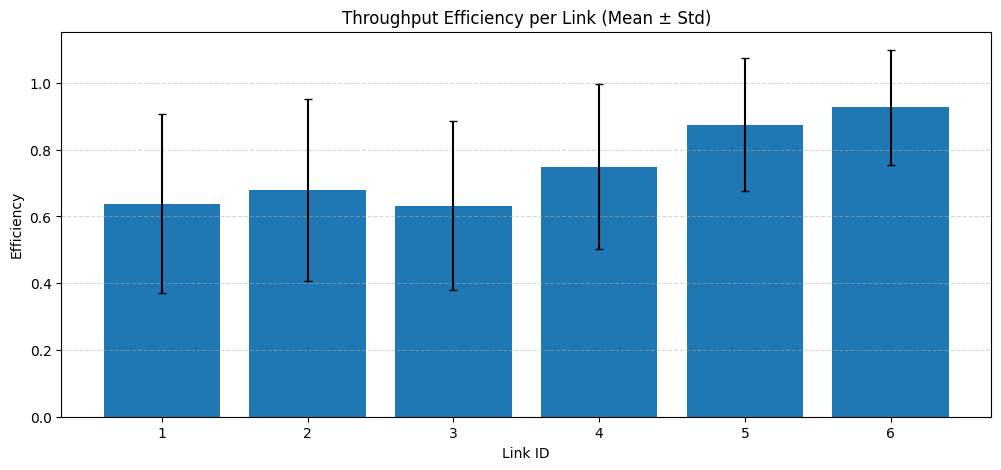

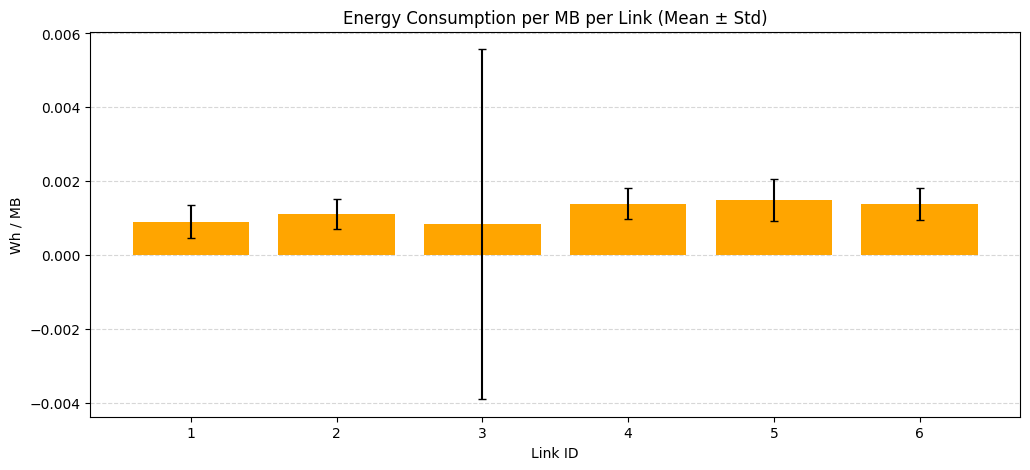

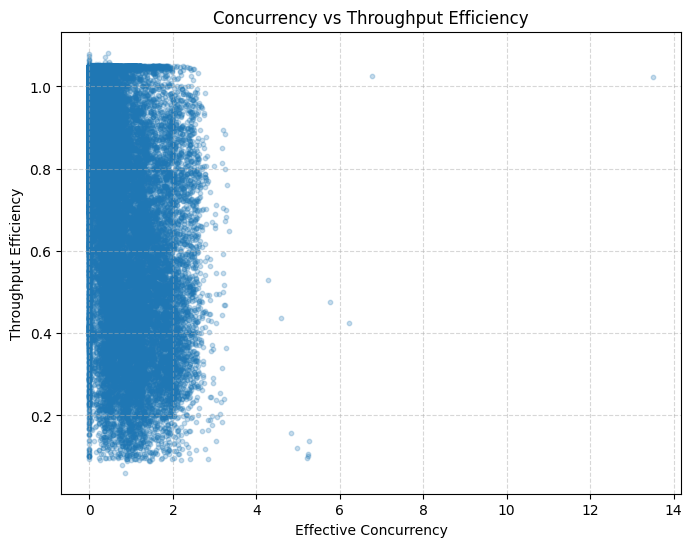

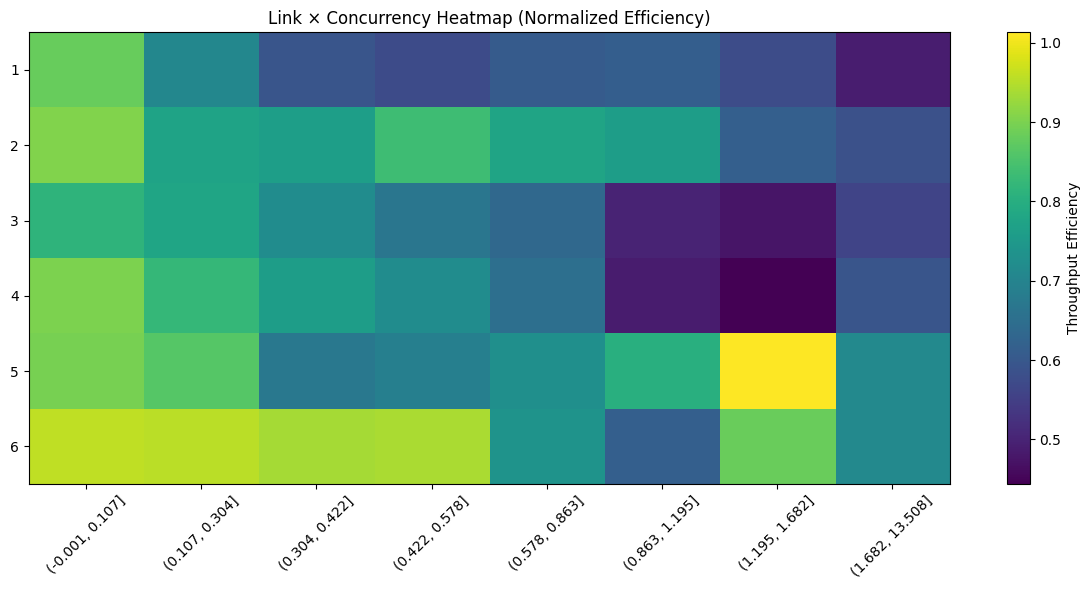


========== CONTROLLED CASE STUDY ==========

        data_bin        bw_bin  best_link  worst_link  energy_best  \
0   (0.154, 6.0]  (0.209, 0.7]        1.0         3.0     0.001249   
1   (0.154, 6.0]    (0.7, 1.0]        3.0         5.0     0.000720   
2   (0.154, 6.0]    (1.0, 1.2]        3.0         5.0     0.000899   
3   (0.154, 6.0]    (1.2, 1.5]        1.0         5.0     0.001479   
4   (0.154, 6.0]    (1.5, 1.7]        1.0         2.0     0.000964   
5   (0.154, 6.0]    (1.7, 1.9]        1.0         2.0     0.001696   
6   (0.154, 6.0]   (1.9, 2.17]        6.0         2.0     0.001529   
7   (0.154, 6.0]   (2.17, 2.4]        5.0         4.0     0.001731   
8     (6.0, 8.0]  (0.209, 0.7]        3.0         5.0     0.000722   
9     (6.0, 8.0]    (0.7, 1.0]        3.0         5.0     0.000678   
10    (6.0, 8.0]    (1.0, 1.2]        3.0         5.0     0.000645   
11    (6.0, 8.0]    (1.2, 1.5]        1.0         5.0     0.000776   
12    (6.0, 8.0]    (1.5, 1.7]        1.0   

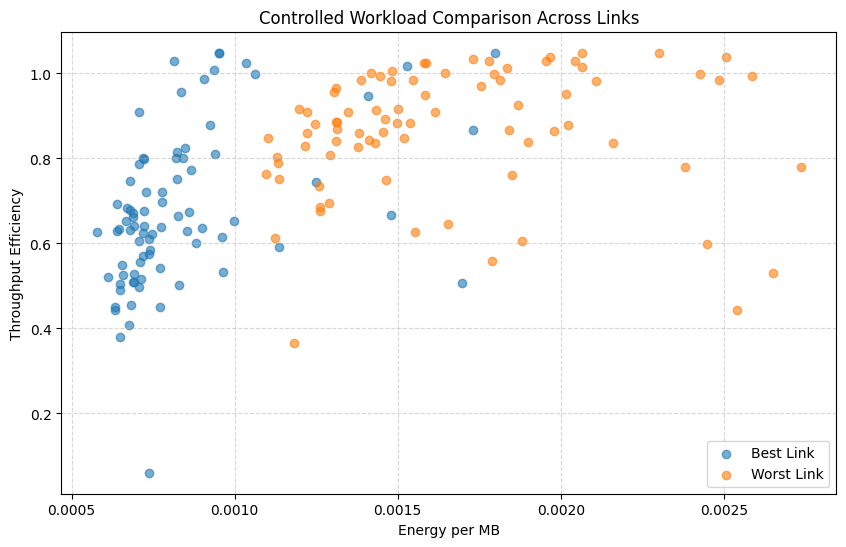

In [21]:
# =========================================================
# LINK-LEVEL PERFORMANCE + ENERGY ANALYSIS (FULL PIPELINE)
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- LAYER 1: STRICT CUSTOM LINK MAPPING ---
LINK_MAP = {
    ("node01", "node05"): "link1",
    ("node03", "node06"): "link2",
    ("node02", "node04"): "link3",
    ("node07", "node08"): "link4",
    ("node09", "node12"): "link5",
    ("node10", "node11"): "link6",

    ("node05", "node01"): "link1",
    ("node06", "node03"): "link2",
    ("node04", "node02"): "link3",
    ("node08", "node07"): "link4",
    ("node12", "node09"): "link5", 
    ("node11", "node10"): "link6",
}

def get_link_id(row):
    pair = tuple(sorted([row["src_node"], row["dst_node"]]))
    link_str = LINK_MAP.get(pair, "unknown")
    if link_str != "unknown":
        return int(link_str.replace("link", ""))
    return np.nan 

# Initialize working DataFrame and apply structural mapping
df_clean = df.copy()
df_clean["link_id"] = df_clean.apply(get_link_id, axis=1)

# Drop any unmapped link rows before running analysis calculations
df_clean = df_clean.dropna(subset=["link_id"])
df_clean["link_id"] = df_clean["link_id"].astype(int)


# --- LAYER 2: CLEANING LAYER 
df_clean = df_clean[
    (df_clean["throughput_mbps"] > 0) &
    (df_clean["data_amount_mb"] > 0) &
    (df_clean["bandwidth_req_mbps"] > 0) &
    (df_clean["total_energy_Wh"] > 0)
].copy()

df_clean = df_clean.reset_index(drop=True)

# Remove extreme outliers (robust analysis)
q_low = df_clean["throughput_mbps"].quantile(0.01)
q_high = df_clean["throughput_mbps"].quantile(0.99)

df_clean = df_clean[
    (df_clean["throughput_mbps"] >= q_low) &
    (df_clean["throughput_mbps"] <= q_high)
]


# --- LAYER 3: ROBUST NORMALIZED METRICS ---
df_clean["throughput_efficiency"] = (
    df_clean["throughput_mbps"] /
    (df_clean["bandwidth_req_mbps"] + 1e-6)
)

df_clean["energy_per_mb"] = (
    df_clean["total_energy_Wh"] /
    (df_clean["data_amount_mb"] + 1e-6)
)

df_clean["energy_efficiency"] = (
    df_clean["data_amount_mb"] /
    (df_clean["total_energy_Wh"] + 1e-6)
)


# --- LAYER 4: CONDITIONED LINK STATISTICS ---
link_stats = df_clean.groupby("link_id").agg({
    "throughput_efficiency": ["mean", "std"],
    "energy_per_mb": ["mean", "std"],
    "energy_efficiency": ["mean", "std"],
    "effective_concurrency": "mean"
})

link_stats.columns = ["_".join(col).strip() for col in link_stats.columns]
link_stats = link_stats.reset_index()


# --- LAYER 5: THROUGHPUT EFFICIENCY PER LINK (WITH VARIANCE) ---
link_sorted = link_stats.sort_values("throughput_efficiency_mean")
plt.figure(figsize=(12,5))
plt.bar(
    link_sorted["link_id"],
    link_sorted["throughput_efficiency_mean"],
    yerr=link_sorted["throughput_efficiency_std"],
    capsize=3
)
plt.title("Throughput Efficiency per Link (Mean ± Std)")
plt.ylabel("Efficiency")
plt.xlabel("Link ID")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()


# --- LAYER 6: ENERGY PER MB PER LINK (ROBUST) ---
link_sorted_energy = link_stats.sort_values("energy_per_mb_mean")
plt.figure(figsize=(12,5))
plt.bar(
    link_sorted_energy["link_id"],
    link_sorted_energy["energy_per_mb_mean"],
    yerr=link_sorted_energy["energy_per_mb_std"],
    capsize=3,
    color="orange"
)
plt.title("Energy Consumption per MB per Link (Mean ± Std)")
plt.ylabel("Wh / MB")
plt.xlabel("Link ID")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()


# --- LAYER 7: CONCURRENCY IMPACT (CLEAN SCATTER) ---
plt.figure(figsize=(8,6))
plt.scatter(
    df_clean["effective_concurrency"],
    df_clean["throughput_efficiency"],
    alpha=0.25,
    s=10
)
plt.title("Concurrency vs Throughput Efficiency")
plt.xlabel("Effective Concurrency")
plt.ylabel("Throughput Efficiency")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


# --- LAYER 8: LINK × CONCURRENCY HEATMAP (IMPROVED) ---
df_clean["conc_bin"] = pd.qcut(
    df_clean["effective_concurrency"],
    q=10,
    duplicates="drop"
)

pivot = df_clean.pivot_table(
    index="link_id",
    columns="conc_bin",
    values="throughput_efficiency",
    aggfunc="mean"
)

plt.figure(figsize=(12,6))
plt.imshow(pivot.fillna(0), aspect="auto", cmap="viridis")
plt.colorbar(label="Throughput Efficiency")
plt.title("Link × Concurrency Heatmap (Normalized Efficiency)")
plt.yticks(range(len(pivot.index)), pivot.index)
plt.xticks(range(len(pivot.columns)), [str(c) for c in pivot.columns], rotation=45)
plt.tight_layout()
plt.show()


# --- LAYER 9: CONTROLLED CASE STUDY ---
df_clean["data_bin"] = pd.qcut(df_clean["data_amount_mb"], q=10, duplicates="drop")
df_clean["bw_bin"] = pd.qcut(df_clean["bandwidth_req_mbps"], q=10, duplicates="drop")

case_groups = df_clean.groupby(["data_bin", "bw_bin"])
case_studies = []

for key, g in case_groups:
    if g["link_id"].nunique() < 2:
        continue

    link_summary = g.groupby("link_id").agg({
        "energy_per_mb": "mean",
        "throughput_efficiency": "mean",
        "effective_concurrency": "mean"
    }).reset_index()

    best = link_summary.loc[link_summary["energy_per_mb"].idxmin()]
    worst = link_summary.loc[link_summary["energy_per_mb"].idxmax()]

    case_studies.append({
        "data_bin": str(key[0]),
        "bw_bin": str(key[1]),
        "best_link": best["link_id"],
        "worst_link": worst["link_id"],
        "energy_best": best["energy_per_mb"],
        "energy_worst": worst["energy_per_mb"],
        "eff_best": best["throughput_efficiency"],
        "eff_worst": worst["throughput_efficiency"],
    })

case_df = pd.DataFrame(case_studies)
print("\n========== CONTROLLED CASE STUDY ==========\n")
print(case_df.head(15))


# --- LAYER 10: VISUAL CASE STUDY ---
plt.figure(figsize=(10,6))
plt.scatter(case_df["energy_best"], case_df["eff_best"], label="Best Link", alpha=0.6)
plt.scatter(case_df["energy_worst"], case_df["eff_worst"], label="Worst Link", alpha=0.6)
plt.title("Controlled Workload Comparison Across Links")
plt.xlabel("Energy per MB")
plt.ylabel("Throughput Efficiency")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [9]:
# =========================================================
# CELL 4A — CLEANING + THROUGHPUT RECONSTRUCTION
# =========================================================

import numpy as np
import pandas as pd

# =========================================================
# INITIAL STATE
# =========================================================

print("\n========== INITIAL DATASET ==========\n")
print("Rows before cleaning:", len(df))

# =========================================================
# 1. CORRUPTION DETECTION
# =========================================================

invalid_mb = (df["MB"] < 0).sum()
invalid_duration = (df["duration_s"] <= 0).sum()
invalid_energy = (df["total_energy_Wh"] < 0).sum()

print("\n========== CORRUPTION REPORT ==========\n")

print(f"Negative MB:          {invalid_mb}")
print(f"Invalid duration:     {invalid_duration}")
print(f"Negative energy:      {invalid_energy}")

# =========================================================
# 2. REMOVE PHYSICALLY IMPOSSIBLE RECORDS
# =========================================================

rows_before = len(df)

df = df[
    (df["MB"] >= 0) &
    (df["duration_s"] > 0) &
    (df["total_energy_Wh"] >= 0)
].copy()

rows_removed = rows_before - len(df)

print("\n========== CLEANING SUMMARY ==========\n")

print("Rows removed:", rows_removed)
print("Rows remaining:", len(df))

# =========================================================
# 3. FAILURE LABELING
# =========================================================

df["execution_failed"] = (
    (df["throughput_mbps"] == 0) &
    (df["jitter_ms"] == 0) &
    (df["packet_loss_percent"] == 0)
)

print("\nFailure rate:",
      round(df["execution_failed"].mean() * 100, 2), "%")

# =========================================================
# 4. THROUGHPUT IMPUTATION FLAG
# =========================================================

df["throughput_imputed"] = (
    df["throughput_mbps"].isna()
)

print("\nMissing throughput:",
      df["throughput_imputed"].sum())

# =========================================================
# 5. THROUGHPUT RECONSTRUCTION
# =========================================================

missing_mask = df["throughput_mbps"].isna()

df.loc[missing_mask, "throughput_mbps"] = (
    (df.loc[missing_mask, "MB"] * 8) /
    df.loc[missing_mask, "duration_s"]
)

print("\n========== RECONSTRUCTION ==========\n")

print("Imputed rows:", missing_mask.sum())

print("Remaining NaNs:",
      df["throughput_mbps"].isna().sum())


========== INITIAL DATASET ==========

Rows before cleaning: 37353

========== CORRUPTION REPORT ==========

Negative MB:          3
Invalid duration:     0
Negative energy:      0

========== CLEANING SUMMARY ==========

Rows removed: 3
Rows remaining: 37350

Failure rate: 2.82 %

Missing throughput: 10280

========== RECONSTRUCTION ==========

Imputed rows: 10280
Remaining NaNs: 0


In [10]:
# =========================================================
# CELL 4B — POST-RECONSTRUCTION VALIDATION
# =========================================================
#
# PURPOSE:
#
# Remove invalid throughput values generated
# during reconstruction/imputation.
#
# Then create final modeling datasets.
# =========================================================

# =========================================================
# 1. INVALID THROUGHPUT DETECTION
# =========================================================

invalid_throughput = (
    df["throughput_mbps"] > 4
).sum()

print("\n========== POST-IMPUTATION VALIDATION ==========\n")

print("Throughput > 4 Mbps:",
      invalid_throughput)

# =========================================================
# 2. REMOVE INVALID THROUGHPUT ROWS
# =========================================================

rows_before = len(df)

df = df[
    df["throughput_mbps"] <= 4
].copy()

rows_removed = rows_before - len(df)

print("\nRows removed:", rows_removed)
print("Rows remaining:", len(df))

# =========================================================
# 3. FINAL DATASET SPLITS
# =========================================================

# ---------------------------------------------------------
# FULL DATASET
# ---------------------------------------------------------

df_full = df.copy().reset_index(drop=True)

# ---------------------------------------------------------
# QoS DATASET
# ---------------------------------------------------------

df_qos = df[
    (df["execution_failed"] == False) &
    (df["throughput_imputed"] == False)
].copy().reset_index(drop=True)

# ---------------------------------------------------------
# ENERGY DATASET
# ---------------------------------------------------------

df_energy = df[
    (df["total_energy_Wh"] > 0)
].copy().reset_index(drop=True)

# =========================================================
# 4. FINAL COUNTS
# =========================================================

print("\n========== FINAL DATASETS ==========\n")

print("Full dataset:   ", len(df_full))
print("QoS dataset:    ", len(df_qos))
print("Energy dataset: ", len(df_energy))

# =========================================================
# 5. FINAL THROUGHPUT STATS
# =========================================================

print("\n========== QoS THROUGHPUT ==========\n")

print("Min :", df_qos["throughput_mbps"].min())
print("Max :", df_qos["throughput_mbps"].max())
print("Mean:", df_qos["throughput_mbps"].mean())
print("Std :", df_qos["throughput_mbps"].std())

# =========================================================
# 6. FINAL INTEGRITY CHECKS
# =========================================================

print("\n========== INTEGRITY CHECKS ==========\n")

print("Imputed rows in QoS:",
      df_qos["throughput_imputed"].sum())

print("Failed rows in QoS:",
      df_qos["execution_failed"].sum())

print("Remaining throughput > 4:",
      (df["throughput_mbps"] > 4).sum())


========== POST-IMPUTATION VALIDATION ==========

Throughput > 4 Mbps: 9

Rows removed: 9
Rows remaining: 37341

========== FINAL DATASETS ==========

Full dataset:    37341
QoS dataset:     26016
Energy dataset:  37225

========== QoS THROUGHPUT ==========

Min : 0.00827
Max : 2.47
Mean: 1.3340888864544895
Std : 0.5993670891690012

========== INTEGRITY CHECKS ==========

Imputed rows in QoS: 0
Failed rows in QoS: 0
Remaining throughput > 4: 0


In [11]:
df_clean.columns

Index(['time', 'MB', 'bandwidth_req_mbps', 'data_amount_mb', 'dst_node',
       'duration_s', 'exec_unit_id', 'jitter_ms', 'packet_loss_percent',
       'src_node', 'throughput_mbps', 'total_energy_Wh', 'total_rx_Wh',
       'total_tx_Wh', 'end_time', 'hour', 'day_of_week', 'is_weekend', 'month',
       'workload_date', 'hour_sin', 'hour_cos', 'effective_concurrency',
       'link_id', 'throughput_efficiency', 'energy_per_mb',
       'energy_efficiency', 'conc_bin', 'data_bin', 'bw_bin'],
      dtype='str')



========== TEMPORAL STATISTICS ==========

========== WEEKDAY VS WEEKEND ==========

         throughput_efficiency                     total_energy_Wh            \
                          mean    median       std            mean    median   
day_type                                                                       
Weekday               0.727607  0.807658  0.281389        0.037038  0.014799   
Weekend               0.724048  0.815789  0.315914        0.039337  0.015908   

                   packet_loss_percent                    
               std                mean median        std  
day_type                                                  
Weekday   0.046079           17.012258    8.5  19.575101  
Weekend   0.043451           19.444318   12.0  20.887856  

========== TIME PERIOD STATS ==========

            throughput_efficiency                     total_energy_Wh  \
                             mean    median       std            mean   
time_period                  

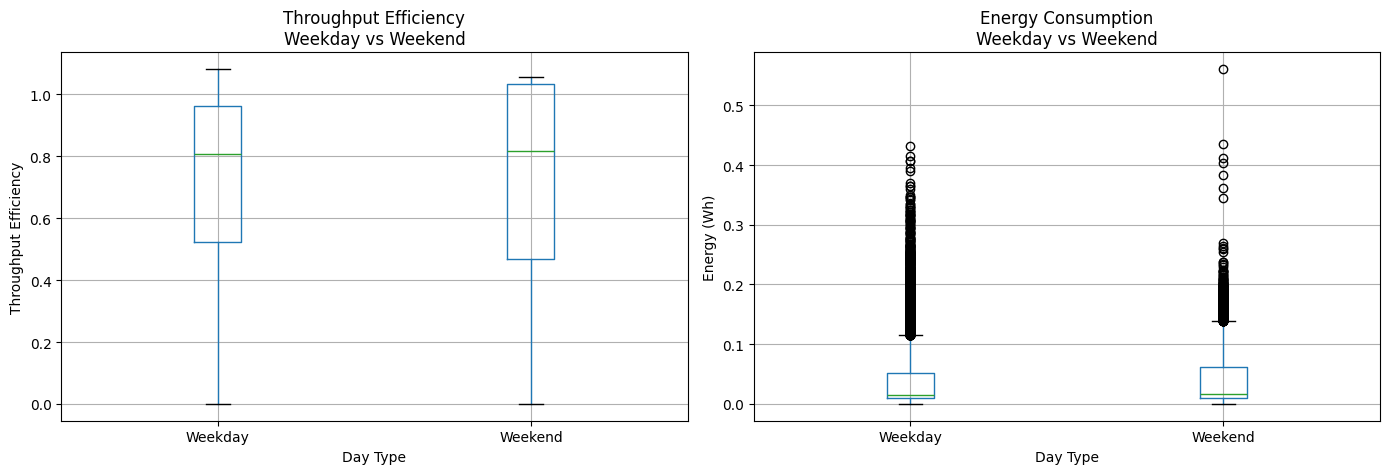

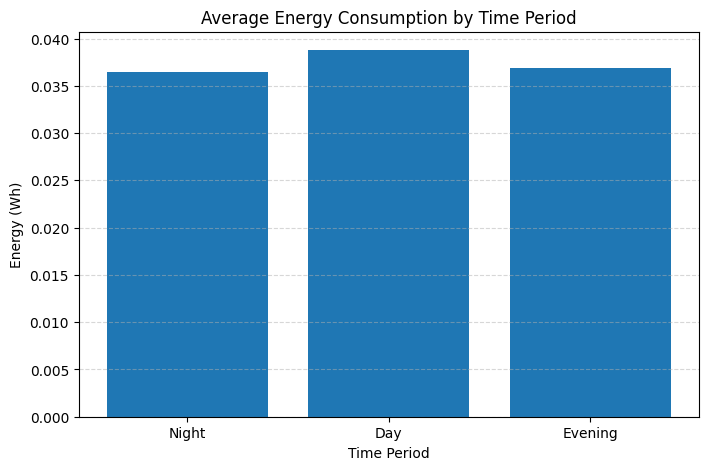

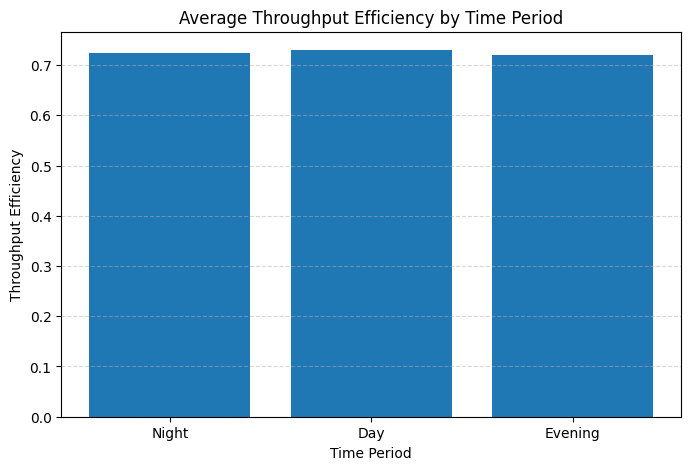

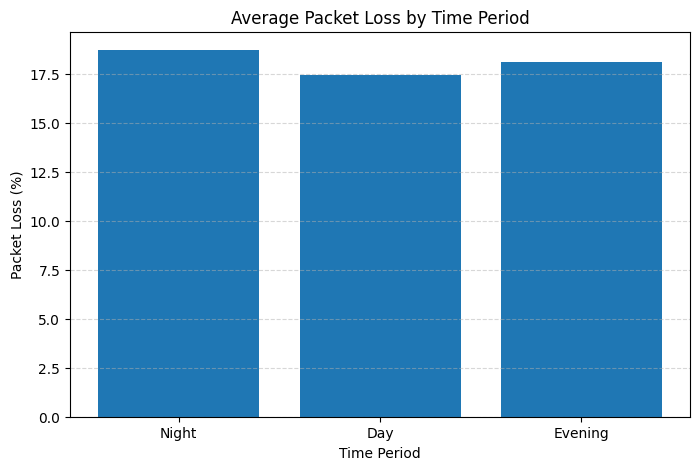

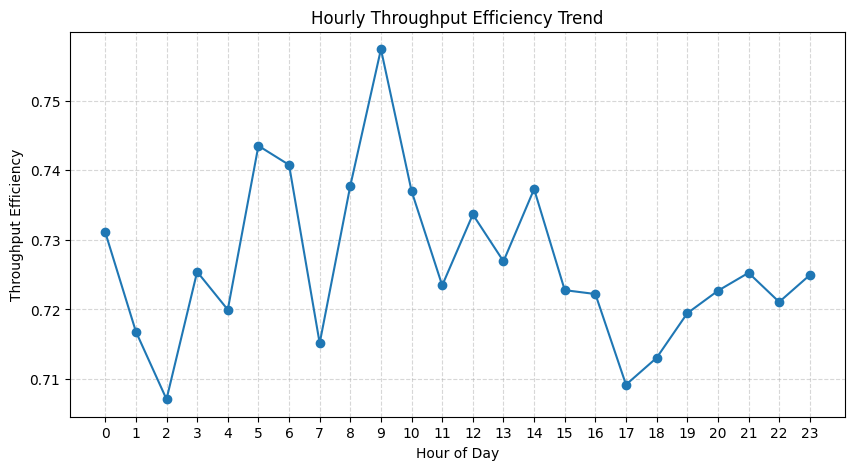

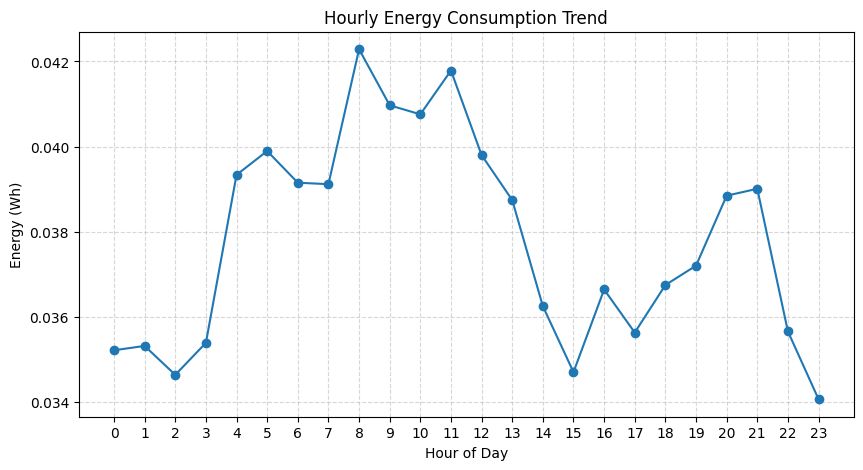

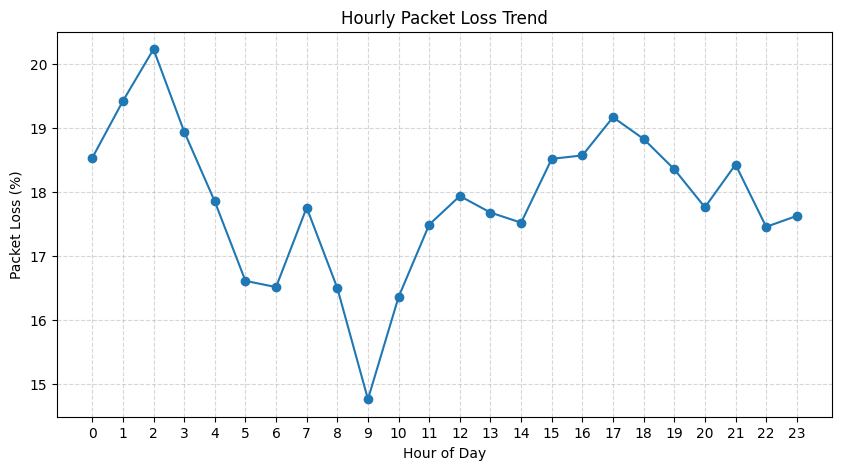

In [12]:
# =========================================================
# TEMPORAL EFFECTS ANALYSIS
# FIGURE 4.3 + FIGURE 4.4
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1. DATASET
# =========================================================

df_plot = df.copy()

# =========================================================
# 2. THROUGHPUT EFFICIENCY
# =========================================================

df_plot["throughput_efficiency"] = (
    df_plot["throughput_mbps"] /
    (df_plot["bandwidth_req_mbps"] + 1e-9)
)

# remove invalid values
df_plot = df_plot.replace([np.inf, -np.inf], np.nan)

df_plot = df_plot.dropna(subset=[
    "throughput_efficiency",
    "total_energy_Wh",
    "packet_loss_percent"
])

# =========================================================
# 3. DAY TYPE LABELS
# =========================================================

df_plot["day_type"] = np.where(
    df_plot["is_weekend"] == 1,
    "Weekend",
    "Weekday"
)

# =========================================================
# 4. TIME PERIOD LABELS
# =========================================================

def time_period(hour):

    if 0 <= hour < 6:
        return "Night"

    elif 6 <= hour < 18:
        return "Day"

    else:
        return "Evening"

df_plot["time_period"] = df_plot["hour"].apply(time_period)

# =========================================================
# 5. STATISTICS
# =========================================================

print("\n")
print("=" * 70)
print("========== TEMPORAL STATISTICS ==========")
print("=" * 70)

# ---------------------------------------------------------
# WEEKDAY VS WEEKEND
# ---------------------------------------------------------

weekday_stats = (
    df_plot.groupby("day_type")[
        [
            "throughput_efficiency",
            "total_energy_Wh",
            "packet_loss_percent"
        ]
    ]
    .agg(["mean", "median", "std"])
)

print("\n========== WEEKDAY VS WEEKEND ==========\n")
print(weekday_stats)

# ---------------------------------------------------------
# TIME PERIOD STATS
# ---------------------------------------------------------

period_stats = (
    df_plot.groupby("time_period")[
        [
            "throughput_efficiency",
            "total_energy_Wh",
            "packet_loss_percent"
        ]
    ]
    .agg(["mean", "median", "std"])
)

print("\n========== TIME PERIOD STATS ==========\n")
print(period_stats)

# =========================================================
# 6. FIGURE 4.3 — DAY-OF-WEEK IMPACT
# =========================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---------------------------------------------------------
# THROUGHPUT EFFICIENCY
# ---------------------------------------------------------

df_plot.boxplot(
    column="throughput_efficiency",
    by="day_type",
    ax=axes[0]
)

axes[0].set_title(
    "Throughput Efficiency\nWeekday vs Weekend"
)

axes[0].set_xlabel("Day Type")
axes[0].set_ylabel("Throughput Efficiency")

# ---------------------------------------------------------
# ENERGY
# ---------------------------------------------------------

df_plot.boxplot(
    column="total_energy_Wh",
    by="day_type",
    ax=axes[1]
)

axes[1].set_title(
    "Energy Consumption\nWeekday vs Weekend"
)

axes[1].set_xlabel("Day Type")
axes[1].set_ylabel("Energy (Wh)")

plt.suptitle("")
plt.tight_layout()
plt.show()

# =========================================================
# 7. FIGURE 4.4 — DAY VS NIGHT PERFORMANCE
# =========================================================

grouped = (
    df_plot.groupby("time_period")[
        [
            "total_energy_Wh",
            "throughput_efficiency",
            "packet_loss_percent"
        ]
    ]
    .mean()
)

# reorder
grouped = grouped.loc[
    ["Night", "Day", "Evening"]
]

# ---------------------------------------------------------
# ENERGY
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    grouped.index,
    grouped["total_energy_Wh"]
)

plt.title(
    "Average Energy Consumption by Time Period"
)

plt.xlabel("Time Period")
plt.ylabel("Energy (Wh)")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

# ---------------------------------------------------------
# THROUGHPUT EFFICIENCY
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    grouped.index,
    grouped["throughput_efficiency"]
)

plt.title(
    "Average Throughput Efficiency by Time Period"
)

plt.xlabel("Time Period")
plt.ylabel("Throughput Efficiency")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

# ---------------------------------------------------------
# PACKET LOSS
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    grouped.index,
    grouped["packet_loss_percent"]
)

plt.title(
    "Average Packet Loss by Time Period"
)

plt.xlabel("Time Period")
plt.ylabel("Packet Loss (%)")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

# =========================================================
# 8. OPTIONAL: HOURLY TRENDS
# =========================================================

hourly = (
    df_plot.groupby("hour")[
        [
            "throughput_efficiency",
            "total_energy_Wh",
            "packet_loss_percent"
        ]
    ]
    .mean()
)

# ---------------------------------------------------------
# THROUGHPUT EFFICIENCY
# ---------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    hourly.index,
    hourly["throughput_efficiency"],
    marker="o"
)

plt.title("Hourly Throughput Efficiency Trend")

plt.xlabel("Hour of Day")
plt.ylabel("Throughput Efficiency")

plt.grid(True, linestyle="--", alpha=0.5)

plt.xticks(range(0, 24))

plt.show()

# ---------------------------------------------------------
# ENERGY
# ---------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    hourly.index,
    hourly["total_energy_Wh"],
    marker="o"
)

plt.title("Hourly Energy Consumption Trend")

plt.xlabel("Hour of Day")
plt.ylabel("Energy (Wh)")

plt.grid(True, linestyle="--", alpha=0.5)

plt.xticks(range(0, 24))

plt.show()

# ---------------------------------------------------------
# PACKET LOSS
# ---------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    hourly.index,
    hourly["packet_loss_percent"],
    marker="o"
)

plt.title("Hourly Packet Loss Trend")

plt.xlabel("Hour of Day")
plt.ylabel("Packet Loss (%)")

plt.grid(True, linestyle="--", alpha=0.5)

plt.xticks(range(0, 24))

plt.show()


========== TARGET VARIABLE STATISTICS (QoS THROUGHPUT) ==========

count    26016.000000
mean         1.334089
std          0.599367
min          0.008270
25%          0.838000
50%          1.300000
75%          1.830000
max          2.470000
Name: throughput_mbps, dtype: float64

Skewness: 0.12138305531136073
Kurtosis: -1.0530952027650313


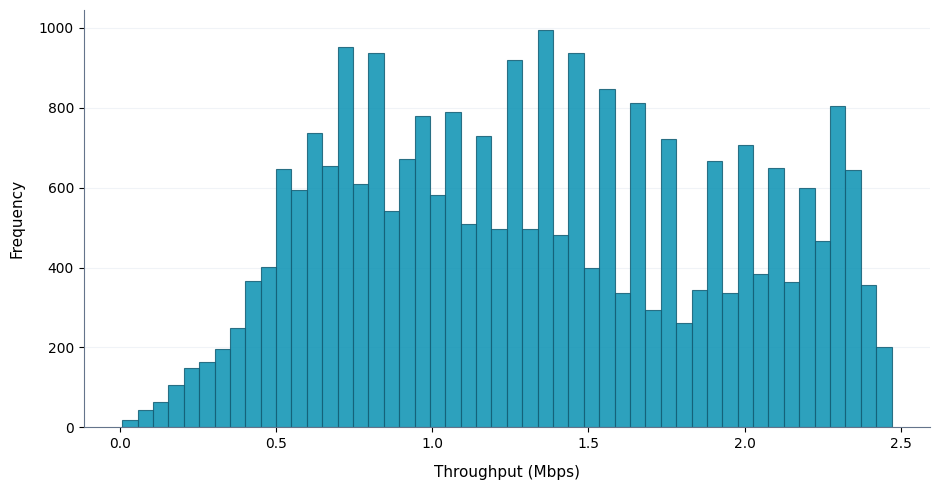

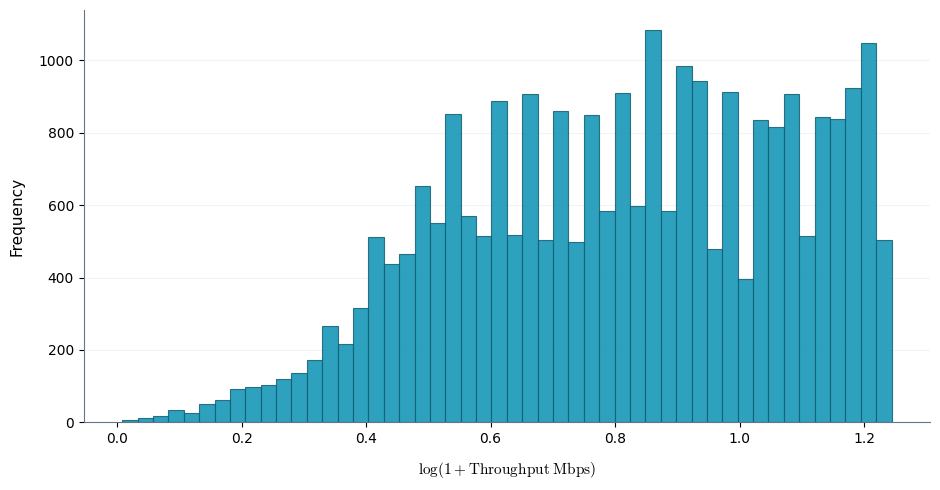

In [13]:
# ==============================================================================
# FIGURE 4.3 — THROUGHPUT VARIABLE DISTRIBUTION
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Apply global Tech/QoS typography settings
plt.rcParams['text.usetex'] = False  
plt.rcParams['mathtext.fontset'] = 'cm'  # Built-in math style matching LaTeX text
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans', 'sans-serif']

df_plot = df_qos.copy()
target = df_plot["throughput_mbps"]

# ==============================================================================
# 1. BASIC STATISTICS (FOR THESIS TEXT)
# ==============================================================================
print("\n========== TARGET VARIABLE STATISTICS (QoS THROUGHPUT) ==========\n")
print(target.describe())
print("\nSkewness:", target.skew())
print("Kurtosis:", target.kurtosis())

# ==============================================================================
# 2. MAIN DISTRIBUTION PLOT
# ==============================================================================
fig, ax = plt.subplots(figsize=(9.5, 5.0))

ax.hist(
    target,
    bins=50,
    alpha=0.85,
    color='#0891b2',      # Tech Cyan / Ocean Blue
    edgecolor='#155e75',  # Deep ocean accent border
    linewidth=0.8
)

# Typography and spacing layout (Titles removed for LaTeX caption processing)
ax.set_xlabel("Throughput (Mbps)", fontsize=11, labelpad=10)
ax.set_ylabel("Frequency", fontsize=11, labelpad=10)

# Configure borders (spines) matching clean technical slate tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)
ax.spines['left'].set_color('#64748b')    # Muted technical slate
ax.spines['bottom'].set_color('#64748b')

# Clean horizontal grid architecture (Optimized for histogram frequency scanning)
ax.grid(True, linestyle='-', alpha=0.5, color='#e2e8f0', axis='y')
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# ==============================================================================
# 3. LOG SCALE VERSION (IMPORTANT FOR NETWORK SYSTEMS / LONG-TAIL QoS)
# ==============================================================================
fig, ax = plt.subplots(figsize=(9.5, 5.0))

ax.hist(
    np.log1p(target),
    bins=50,
    alpha=0.85,
    color='#0891b2',
    edgecolor='#155e75',
    linewidth=0.8
)

# Typography and spacing layout (Titles removed for LaTeX caption processing)
ax.set_xlabel(r"$\log(1 + \mathrm{Throughput}\;\mathrm{Mbps})$", fontsize=11, labelpad=10)
ax.set_ylabel("Frequency", fontsize=11, labelpad=10)

# Configure borders (spines) matching clean technical slate tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)
ax.spines['left'].set_color('#64748b')
ax.spines['bottom'].set_color('#64748b')

# Clean horizontal grid architecture
ax.grid(True, linestyle='-', alpha=0.5, color='#e2e8f0', axis='y')
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


========== LINK FREQUENCY DISTRIBUTION ==========

   link_id  count
0        1   3571
1        2   4971
2        3   3416
3        4   4170
4        5   4783
5        6   4641

========== STATISTICS ==========

Total unique links : 6
Total rows         : 25552
Most frequent link : 2
Max frequency      : 4971
Min frequency      : 3416


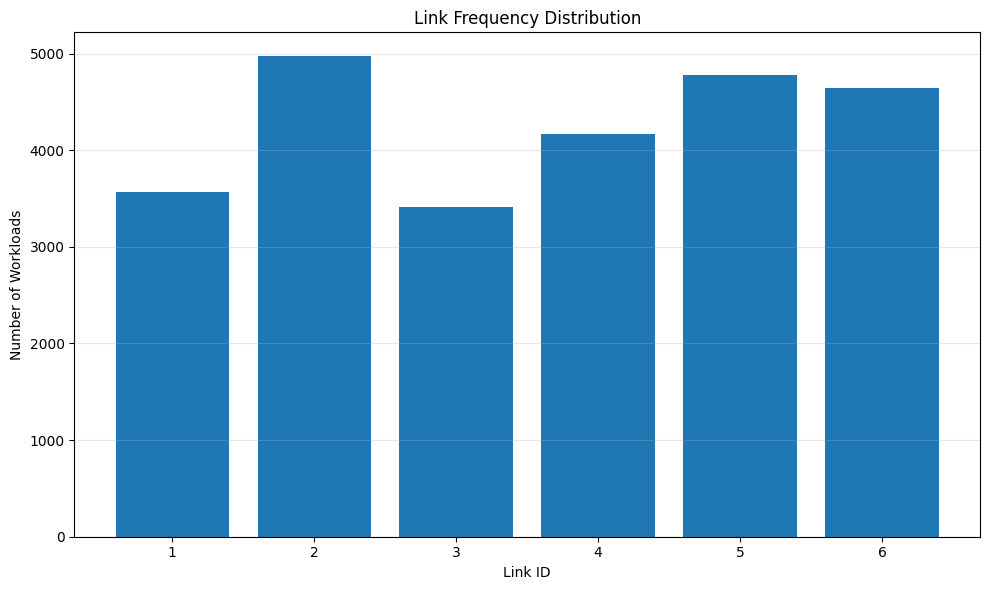


========== PERCENTAGE DISTRIBUTION ==========

   link_id  count  percentage
0        1   3571   13.975423
1        2   4971   19.454446
2        3   3416   13.368817
3        4   4170   16.319662
4        5   4783   18.718691
5        6   4641   18.162962


In [14]:
# =========================================================
# LINK FREQUENCY DISTRIBUTION
# =========================================================

import pandas as pd
import matplotlib.pyplot as plt

link_counts = (
    df_clean["link_id"]
    .value_counts()
    .sort_index()
)

link_freq_df = pd.DataFrame({

    "link_id": link_counts.index,
    "count": link_counts.values
})

print("\n========== LINK FREQUENCY DISTRIBUTION ==========\n")

print(link_freq_df)
print("\n========== STATISTICS ==========\n")

print("Total unique links :", df_clean["link_id"].nunique())
print("Total rows         :", len(df_clean))
print("Most frequent link :", link_counts.idxmax())
print("Max frequency      :", link_counts.max())
print("Min frequency      :", link_counts.min())

plt.figure(figsize=(10, 6))

plt.bar(
    link_freq_df["link_id"].astype(str),
    link_freq_df["count"]
)

plt.title(
    "Link Frequency Distribution"
)

plt.xlabel("Link ID")
plt.ylabel("Number of Workloads")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

link_freq_df["percentage"] = (
    link_freq_df["count"] /
    link_freq_df["count"].sum()
) * 100

print("\n========== PERCENTAGE DISTRIBUTION ==========\n")

print(link_freq_df)

26016

========== BASE ==========
Actual features used (36 total):
  1. day_of_week
  2. is_weekend
  3. hour_sin
  4. hour_cos
  5. data_amount_mb
  6. bandwidth_req_mbps
  7. src_node_node01
  8. src_node_node02
  9. src_node_node03
  10. src_node_node04
  11. src_node_node05
  12. src_node_node06
  13. src_node_node07
  14. src_node_node08
  15. src_node_node09
  16. src_node_node10
  17. src_node_node11
  18. src_node_node12
  19. dst_node_node01
  20. dst_node_node02
  21. dst_node_node03
  22. dst_node_node04
  23. dst_node_node05
  24. dst_node_node06
  25. dst_node_node07
  26. dst_node_node08
  27. dst_node_node09
  28. dst_node_node10
  29. dst_node_node11
  30. dst_node_node12
  31. link_id_1
  32. link_id_2
  33. link_id_3
  34. link_id_4
  35. link_id_5
  36. link_id_6
----------------------------------------

========== BASE ==========
Encoded Features: 36
----------------------------------------
MAE : 0.26816284526022954
RMSE: 0.39449566483285886
R2  : 0.5620435010581766

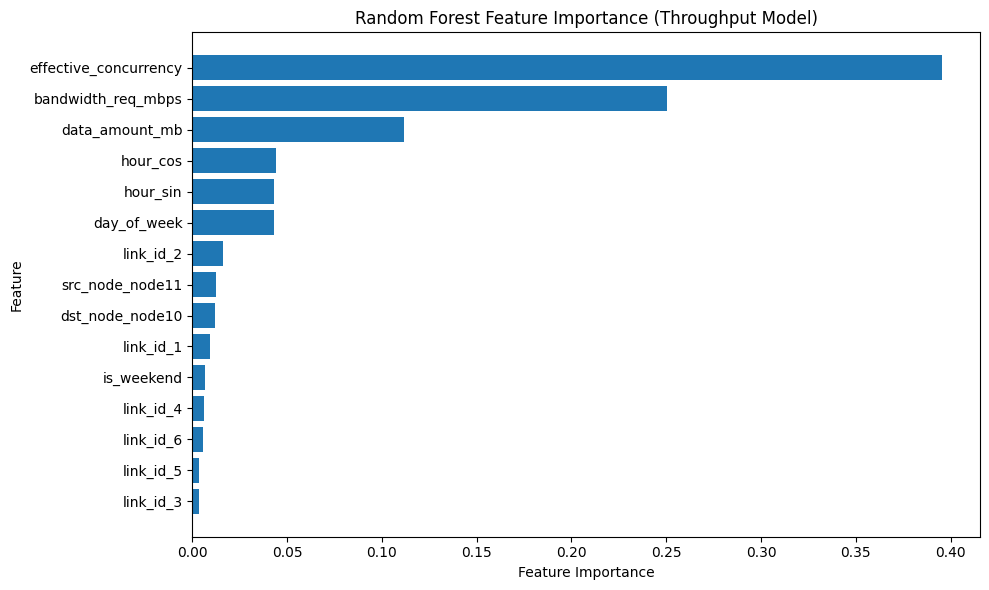

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
import numpy as np
import pandas as pd

# =========================================================
# OPTIONAL: CREATE LINK ID (if not already safe)
# =========================================================
df_qos["link_id"] = df_qos.apply(get_link_id, axis=1)

# =========================================================
# TARGET DEFINITION
# =========================================================
TARGET = "throughput_mbps"

# =========================================================
# FEATURE SET DEFINITIONS
# =========================================================
TEMP_FEATURES = ["day_of_week", "is_weekend", "hour_sin", "hour_cos"]
WORKLOAD_FEATURES = ["data_amount_mb", "bandwidth_req_mbps"]
TOPOLOGY_FEATURES = ["src_node", "dst_node", "link_id"]
CONCURRENCY_FEATURES = ["effective_concurrency"]

#"peak_concurrency",
BASE_FEATURES = TEMP_FEATURES + WORKLOAD_FEATURES + TOPOLOGY_FEATURES
CONC_FEATURES = BASE_FEATURES + CONCURRENCY_FEATURES
FULL_FEATURES = CONC_FEATURES

# =========================================================
# DATASET PREPARATION
# =========================================================
df_model = df_qos.copy()
print(len(df_model))
# =========================================================
# MODEL EVALUATION FUNCTION
# =========================================================
def evaluate_model(X, y):

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    return mae, rmse, r2


# =========================================================
# EXPERIMENT STORAGE
# =========================================================
results = []

# =========================================================
# EXPERIMENT RUNNER (WITH ONE-HOT ENCODING FIX)
# =========================================================
def run_experiment(name, features):

    # -------------------------
    # select features
    # -------------------------
    X = df_model[features].copy()
    y = df_model[TARGET].copy()

    # -------------------------
    # ONE-HOT ENCODING FIX
    # -------------------------
    categorical_cols = [
        col for col in ["src_node", "dst_node", "link_id"]
        if col in X.columns
    ]

    X = pd.get_dummies(X, columns=categorical_cols)

    print(f"\n========== {name} ==========")
    print(f"Actual features used ({len(X.columns)} total):")
    for i, col in enumerate(X.columns, 1):
        print(f"  {i}. {col}")
    print("-" * 40)

    
    # -------------------------
    # evaluate
    # -------------------------
    mae, rmse, r2 = evaluate_model(X, y)

    results.append({
        "model": name,
        "features_count": X.shape[1],   # after encoding
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print(f"\n========== {name} ==========")
    print(f"Encoded Features: {X.shape[1]}")
    print("-" * 40)
    print("MAE :", mae)
    print("RMSE:", rmse)
    print("R2  :", r2)

# =========================================================
# RUN ABLATION EXPERIMENTS
# =========================================================
run_experiment("BASE", BASE_FEATURES)

run_experiment(
    "BASE + CONCURRENCY",
    CONC_FEATURES
)

run_experiment(
    "FULL MODEL",
    FULL_FEATURES
)

# =========================================================
# SUMMARY TABLE
# =========================================================
results_df = pd.DataFrame(results).sort_values("R2", ascending=False)

print("\n========== MODEL COMPARISON ==========")
print(results_df)

print("\n========== BEST MODEL ==========")
print(results_df.iloc[0])



# =========================================================
# FEATURE IMPORTANCE ANALYSIS (FULL MODEL)
# =========================================================
import matplotlib.pyplot as plt

# -------------------------
# rebuild FULL MODEL dataset
# -------------------------
X_full = df_model[FULL_FEATURES].copy()
y_full = df_model[TARGET].copy()

categorical_cols = [
    col for col in ["src_node", "dst_node", "link_id"]
    if col in X_full.columns
]
X_full = pd.get_dummies(X_full, columns=categorical_cols)

# -------------------------
# train/test split
# -------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42
)

# -------------------------
# train model
# -------------------------
full_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)
full_model.fit(X_train, y_train)

# =========================================================
# FEATURE IMPORTANCE TABLE
# =========================================================
importance_df = pd.DataFrame({
    "feature": X_full.columns,
    "importance": full_model.feature_importances_
})
importance_df = importance_df.sort_values(
    "importance", ascending=False
)

print("\n========== FEATURE IMPORTANCE ==========")
print(importance_df)

# =========================================================
# TOP-N FEATURE IMPORTANCE PLOT
# =========================================================
TOP_N = 15
top_features = importance_df.head(TOP_N)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance (Throughput Model)")
plt.tight_layout()
plt.show()

In [17]:
df_qos.columns

Index(['time', 'MB', 'bandwidth_req_mbps', 'data_amount_mb', 'dst_node',
       'duration_s', 'exec_unit_id', 'jitter_ms', 'packet_loss_percent',
       'src_node', 'throughput_mbps', 'total_energy_Wh', 'total_rx_Wh',
       'total_tx_Wh', 'end_time', 'hour', 'day_of_week', 'is_weekend', 'month',
       'workload_date', 'hour_sin', 'hour_cos', 'effective_concurrency',
       'execution_failed', 'throughput_imputed', 'link_id'],
      dtype='str')

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
import numpy as np
import pandas as pd

# =========================================================
# TARGET DEFINITION
# =========================================================
TARGET = "throughput_mbps"
df_qos["link_id"] = df_qos.apply(get_link_id, axis=1)
# =========================================================
# FEATURE SET DEFINITIONS
# =========================================================

TEMP_FEATURES = [
    "day_of_week",
    "is_weekend",
    "hour_sin",
    "hour_cos"
]

WORKLOAD_FEATURES = [
    "data_amount_mb",
    "bandwidth_req_mbps"
]

TOPOLOGY_FEATURES = [
    "src_node",
    "dst_node",
    "link_id"
]

CONCURRENCY_FEATURES = [
    #"peak_concurrency",
    "effective_concurrency"
]

# =========================================================
# CATEGORICAL FEATURES
# =========================================================

CATEGORICAL_FEATURES = [
    "src_node",
    "dst_node",
    "link_id"
]

# =========================================================
# FEATURE GROUPS (ABLATION STUDY)
# =========================================================

BASE_FEATURES = (
    TEMP_FEATURES +
    WORKLOAD_FEATURES +
    TOPOLOGY_FEATURES
)

CONC_FEATURES = (
    BASE_FEATURES +
    CONCURRENCY_FEATURES
)

FULL_FEATURES = CONC_FEATURES

# =========================================================
# DATASET PREPARATION
# =========================================================

df_model = df_qos.copy()

# =========================================================
# MODEL EVALUATION FUNCTION
# =========================================================

def evaluate_model(X, y):

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )

    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    return mae, rmse, r2

# =========================================================
# EXPERIMENT RUNNER
# =========================================================

results = []

def run_experiment(name, features):

    # ---------------------------------------------
    # Select Features
    # ---------------------------------------------

    X = df_model[features].copy()
    y = df_model[TARGET].copy()

    # ---------------------------------------------
    # Apply One-Hot Encoding
    # ---------------------------------------------

    categorical_cols = [
        col for col in CATEGORICAL_FEATURES
        if col in X.columns
    ]

    X = pd.get_dummies(
        X,
        columns=categorical_cols,
        drop_first=False
    )

    # ---------------------------------------------
    # Evaluate Model
    # ---------------------------------------------

    mae, rmse, r2 = evaluate_model(X, y)

    # ---------------------------------------------
    # Store Results
    # ---------------------------------------------

    results.append({
        "model": name,
        "features_count": X.shape[1],
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    # ---------------------------------------------
    # Print Results
    # ---------------------------------------------

    print(f"\n========== {name} ==========")
    print(f"Original Features Used ({len(features)}):")
    print(", ".join(features))

    print("\nEncoded Feature Count:", X.shape[1])

    print("-" * 40)

    print("MAE :", mae)
    print("RMSE:", rmse)
    print("R2  :", r2)

# =========================================================
# RUN ABLATION EXPERIMENTS
# =========================================================

run_experiment("BASE", BASE_FEATURES)

run_experiment(
    "BASE + CONCURRENCY",
    CONC_FEATURES
)

run_experiment(
    "FULL MODEL",
    FULL_FEATURES
)

# =========================================================
# SUMMARY TABLE
# =========================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "R2",
    ascending=False
)

print("\n========== MODEL COMPARISON ==========")
print(results_df)

print("\n========== BEST MODEL ==========")
print(results_df.iloc[0])


========== BASE ==========
Original Features Used (9):
day_of_week, is_weekend, hour_sin, hour_cos, data_amount_mb, bandwidth_req_mbps, src_node, dst_node, link_id

Encoded Feature Count: 36
----------------------------------------
MAE : 0.2668505072605182
RMSE: 0.39098746902718307
R2  : 0.5607675276257401

========== BASE + CONCURRENCY ==========
Original Features Used (10):
day_of_week, is_weekend, hour_sin, hour_cos, data_amount_mb, bandwidth_req_mbps, src_node, dst_node, link_id, effective_concurrency

Encoded Feature Count: 37
----------------------------------------
MAE : 0.21365426738854823
RMSE: 0.3269955767774778
R2  : 0.6927778538191927

========== FULL MODEL ==========
Original Features Used (10):
day_of_week, is_weekend, hour_sin, hour_cos, data_amount_mb, bandwidth_req_mbps, src_node, dst_node, link_id, effective_concurrency

Encoded Feature Count: 37
----------------------------------------
MAE : 0.21365426738854823
RMSE: 0.32699557677747787
R2  : 0.6927778538191927

===

In [18]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor # Highly recommended for network metrics

# =========================================================
# TUNING CONFIGURATION
# =========================================================
# Define hyperparameter grid for tuning

df_qos["link_id"] = df_qos.apply(get_link_id, axis=1)

RF_PARAMS = {
    'n_estimators': [100, 200],
    'max_depth': [8, 16, None],
    'min_samples_leaf': [1, 2]
}

XGB_PARAMS = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.1],
    'max_depth': [3, 6]
}

# =========================================================
# TUNING & EVALUATION ENGINE
# =========================================================
def tune_and_evaluate(X, y, model_type="RF"):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    if model_type == "RF":
        model = GridSearchCV(RandomForestRegressor(random_state=42), RF_PARAMS, cv=3, n_jobs=-1)
    else:
        model = GridSearchCV(XGBRegressor(objective='reg:squarederror'), XGB_PARAMS, cv=3, n_jobs=-1)
        
    model.fit(X_train, y_train)
    best_model = model.best_estimator_
    pred = best_model.predict(X_test)
    
    return mean_absolute_error(y_test, pred), np.sqrt(mean_squared_error(y_test, pred)), r2_score(y_test, pred), best_model

# =========================================================
# EXPERIMENT RUNNER
# =========================================================
results = []

def run_experiment(name, features, model_type):
    X = df_model[features].copy()
    y = df_model[TARGET].copy()

    categorical_cols = [
        col for col in ["src_node", "dst_node", "link_id"]
        if col in X.columns
    ]
    
    X = pd.get_dummies(X, columns=categorical_cols, drop_first=False)

    mae, rmse, r2, model = tune_and_evaluate(X, y, model_type)
    
    results.append({
        "Model Type": f"{model_type} ({name})",
        "R2": r2,
        "RMSE": rmse
    })
    print(f"Finished {model_type} for {name}: R2={r2:.4f}")

# =========================================================
# EXECUTE COMPARATIVE ABLATION
# =========================================================
configs = [("BASE", BASE_FEATURES), ("FULL", FULL_FEATURES)]

for name, feats in configs:
    run_experiment(name, feats, "RF")
    run_experiment(name, feats, "XGB")

results_df = pd.DataFrame(results).sort_values("R2", ascending=False)
print("\n========== FINAL MODEL COMPARISON ==========")
print(results_df)

ModuleNotFoundError: No module named 'xgboost'

In [16]:
# =========================================================
# CELL — QoS CLASSIFICATION (THROUGHPUT EFFICIENCY)
# =========================================================
#

# GOAL:
#
# Predict QoS degradation states using:
#   - workload features
#   - topology structure
#   - temporal dynamics
#   - concurrency pressure
#
# TARGET:
#
# throughput_efficiency =
#     throughput_mbps / bandwidth_req_mbps
#
# This models:
#   "How efficiently did the system satisfy demand?"
#
# =========================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

# =========================================================
# 1. CLEAN MODELING DATASET
# =========================================================

df_model = df_qos.copy()

df_model = df_model[
    (df_model["execution_failed"] == False) &
    (df_model["throughput_imputed"] == False)
].copy()

df_model = df_model.reset_index(drop=True)

print("\n========== CLEAN DATASET ==========\n")
print("Rows:", len(df_model))

# =========================================================
# 2. THROUGHPUT EFFICIENCY TARGET
# =========================================================

df_model["throughput_efficiency"] = (
    df_model["throughput_mbps"] /
    df_model["bandwidth_req_mbps"]
)

# remove invalid values
df_model = df_model.replace([np.inf, -np.inf], np.nan)

df_model = df_model.dropna(
    subset=["throughput_efficiency"]
)

print("\n========== THROUGHPUT EFFICIENCY ==========\n")

print(df_model["throughput_efficiency"].describe())

# =========================================================
# 3. FEATURE SET
# =========================================================

FEATURES = [

    # -----------------------------------------------------
    # TEMPORAL
    # -----------------------------------------------------

    "day_of_week",
    "is_weekend",
    "hour_sin",
    "hour_cos",

    # -----------------------------------------------------
    # WORKLOAD
    # -----------------------------------------------------

    "data_amount_mb",
    "bandwidth_req_mbps",

    # -----------------------------------------------------
    # TOPOLOGY
    # -----------------------------------------------------

    "src_node",
    "dst_node",
    "link_id",

    # -----------------------------------------------------
    # CONCURRENCY
    # -----------------------------------------------------

    #"peak_concurrency",
    "effective_concurrency",
]

# =========================================================
# 4. SAFETY CHECK
# =========================================================

missing = [
    f for f in FEATURES
    if f not in df_model.columns
]

if len(missing) > 0:
    raise ValueError(f"Missing features: {missing}")

print("\n========== FEATURES ==========\n")

print("Number of features:", len(FEATURES))

for f in FEATURES:
    print(f)

# =========================================================
# 5. MODELS
# =========================================================

models = {

    "RandomForest": RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    ),

    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=100,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_depth=8,
        learning_rate=0.05,
        max_iter=300,
        random_state=42
    )
}

# =========================================================
# 6. MULTI-CLASS EXPERIMENTS
# =========================================================

CLASS_CONFIGS = [3, 5, 10]

all_results = []

# =========================================================
# 7. MAIN LOOP
# =========================================================

for NUM_CLASSES in CLASS_CONFIGS:

    print("\n")
    print("=" * 70)
    print(f"========== QoS CLASSIFICATION ({NUM_CLASSES} CLASSES) ==========")
    print("=" * 70)

    # -----------------------------------------------------
    # CREATE QUANTILE CLASSES
    # -----------------------------------------------------

    df_model["efficiency_class"] = pd.qcut(
        df_model["throughput_efficiency"],
        q=NUM_CLASSES,
        labels=False,
        duplicates="drop"
    )

    # -----------------------------------------------------
    # SPLIT
    # -----------------------------------------------------

    X = df_model[FEATURES]
    y = df_model["efficiency_class"]


    categorical_cols = ["src_node", "dst_node", "link_id"]
    # Check which categorical columns actually exist in X
    categorical_cols = [col for col in categorical_cols if col in X.columns]
    
    if categorical_cols:
        print(f"\nOne-hot encoding: {categorical_cols}")
        X = pd.get_dummies(X, columns=categorical_cols, drop_first=False)
        print(f"Features after encoding: {X.shape[1]}")

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    print("\nTrain size:", len(X_train))
    print("Test size :", len(X_test))

    # -----------------------------------------------------
    # MODEL LOOP
    # -----------------------------------------------------

    for model_name, model in models.items():

        print("\n")
        print("-" * 60)
        print(f"{model_name} ({NUM_CLASSES} classes)")
        print("-" * 60)

        # -------------------------------------------------
        # TRAIN
        # -------------------------------------------------

        model.fit(X_train, y_train)

        # -------------------------------------------------
        # PREDICT
        # -------------------------------------------------

        pred = model.predict(X_test)

        # -------------------------------------------------
        # METRICS
        # -------------------------------------------------

        acc = accuracy_score(y_test, pred)

        f1_macro = f1_score(
            y_test,
            pred,
            average="macro"
        )

        print("\nAccuracy :", round(acc, 4))
        print("F1 Macro :", round(f1_macro, 4))

        # -------------------------------------------------
        # REPORTS
        # -------------------------------------------------

        print("\nClassification Report:\n")

        print(
            classification_report(
                y_test,
                pred
            )
        )

        print("\nConfusion Matrix:\n")

        print(
            confusion_matrix(
                y_test,
                pred
            )
        )

        # -------------------------------------------------
        # STORE RESULTS
        # -------------------------------------------------

        all_results.append({

            "classes": NUM_CLASSES,
            "model": model_name,

            "accuracy": acc,
            "f1_macro": f1_macro
        })

# =========================================================
# 8. FINAL COMPARISON TABLE
# =========================================================

results_df = pd.DataFrame(all_results)

results_df = results_df.sort_values(
    by=["f1_macro", "accuracy"],
    ascending=False
)

print("\n")
print("=" * 70)
print("========== FINAL MODEL COMPARISON ==========")
print("=" * 70)

print(results_df)

# =========================================================
# 9. BEST CONFIGURATION
# =========================================================

print("\n")
print("=" * 70)
print("========== BEST CONFIGURATION ==========")
print("=" * 70)

print(results_df.iloc[0])

# =========================================================
# 10. SELECT BEST MODEL
# =========================================================
import joblib
best_row = results_df.iloc[0]

best_classes = best_row["classes"]
best_model_name = best_row["model"]

print("\nBEST MODEL:", best_model_name)
print("BEST CLASSES:", best_classes)

# =========================================================
# 11. RETRAIN BEST MODEL ON FULL DATA
# =========================================================

df_model["efficiency_class"] = pd.qcut(
    df_model["throughput_efficiency"],
    q=best_classes,
    labels=False,
    duplicates="drop"
)

X = df_model[FEATURES]
y = df_model["efficiency_class"]

categorical_cols = ["src_node", "dst_node", "link_id"]
categorical_cols = [c for c in categorical_cols if c in X.columns]

X = pd.get_dummies(X, columns=categorical_cols, drop_first=False)

best_model = models[best_model_name]
best_model.fit(X, y)

# =========================================================
# 12. SAVE ARTIFACTS
# =========================================================
'''
joblib.dump(best_model, "qos_model.pkl")
joblib.dump(X.columns.tolist(), "qos_feature_columns.pkl")
joblib.dump({
    "classes": best_classes,
    "model": best_model_name,
    "feature_cols": X.columns.tolist(),
    "categorical_cols": categorical_cols
}, "qos_meta.pkl")

print("\nQoS MODEL SAVED")
'''


========== CLEAN DATASET ==========

Rows: 26016

========== THROUGHPUT EFFICIENCY ==========

count    26016.000000
mean         0.749832
std          0.289832
min          0.005477
25%          0.496625
50%          0.837500
75%          1.040000
max          1.060000
Name: throughput_efficiency, dtype: float64

========== FEATURES ==========

Number of features: 10
day_of_week
is_weekend
hour_sin
hour_cos
data_amount_mb
bandwidth_req_mbps
src_node
dst_node
link_id
effective_concurrency


========== QoS CLASSIFICATION (3 CLASSES) ==========

One-hot encoding: ['src_node', 'dst_node', 'link_id']
Features after encoding: 37

Train size: 20812
Test size : 5204


------------------------------------------------------------
RandomForest (3 classes)
------------------------------------------------------------

Accuracy : 0.7806
F1 Macro : 0.78

Classification Report:

              precision    recall  f1-score   support

           0       0.79      0.79      0.79      1735
           1 

'\njoblib.dump(best_model, "qos_model.pkl")\njoblib.dump(X.columns.tolist(), "qos_feature_columns.pkl")\njoblib.dump({\n    "classes": best_classes,\n    "model": best_model_name,\n    "feature_cols": X.columns.tolist(),\n    "categorical_cols": categorical_cols\n}, "qos_meta.pkl")\n\nprint("\nQoS MODEL SAVED")\n'

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

import numpy as np
import pandas as pd

# =========================================================
# 1. TARGET
# =========================================================

TARGET = "MB"

# =========================================================
# 2. DATASET
# =========================================================

df_model = df.copy()

# remove failed executions
df_model = df_model[
    df_model["execution_failed"] == False
].copy()

df_model = df_model.reset_index(drop=True)

print("\n========== MB MODEL DATASET ==========\n")

print("Rows:", len(df_model))

# =========================================================
# 3. FEATURE SETS
# =========================================================

TEMP_FEATURES = [

    "day_of_week",
    "is_weekend",
    "hour_sin",
    "hour_cos",
]

# IMPORTANT:
# data_amount_mb = requested data
# MB = actual transferred data (target)

WORKLOAD_FEATURES = [

    "data_amount_mb",
    "bandwidth_req_mbps",
]

TOPOLOGY_FEATURES = [

    "src_node_id",
    "dst_node_id",
    "link_id",
]

CONCURRENCY_FEATURES = [

    "peak_concurrency",
    "effective_concurrency",
]

# =========================================================
# 4. ABLATION FEATURE GROUPS
# =========================================================

BASE_FEATURES = (
    TEMP_FEATURES +
    WORKLOAD_FEATURES +
    TOPOLOGY_FEATURES
)

CONC_FEATURES = (
    BASE_FEATURES +
    CONCURRENCY_FEATURES
)

FULL_FEATURES = CONC_FEATURES

# =========================================================
# 5. SAFETY CHECK
# =========================================================

ALL_FEATURES = FULL_FEATURES

missing = [
    f for f in ALL_FEATURES
    if f not in df_model.columns
]

if len(missing) > 0:
    raise ValueError(f"Missing features: {missing}")

# =========================================================
# 6. MODEL EVALUATION FUNCTION
# =========================================================

def evaluate_model(X, y):

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )

    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    )

    # -----------------------------------------------------
    # TRAIN
    # -----------------------------------------------------

    model.fit(X_train, y_train)

    # -----------------------------------------------------
    # PREDICT
    # -----------------------------------------------------

    pred = model.predict(X_test)

    # -----------------------------------------------------
    # METRICS
    # -----------------------------------------------------

    mae = mean_absolute_error(y_test, pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, pred)
    )

    r2 = r2_score(y_test, pred)

    return mae, rmse, r2

# =========================================================
# 7. EXPERIMENT RUNNER
# =========================================================

results = []

def run_experiment(name, features):

    X = df_model[features].copy()

    y = df_model[TARGET].copy()

    mae, rmse, r2 = evaluate_model(X, y)

    results.append({

        "model": name,
        "features_count": len(features),

        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    # -----------------------------------------------------
    # PRINT RESULTS
    # -----------------------------------------------------

    print(f"\n========== {name} ==========")

    print(
        f"Features Used ({len(features)}): "
        f"{', '.join(features)}"
    )

    print("-" * 30)

    print("MAE :", mae)
    print("RMSE:", rmse)
    print("R2  :", r2)

# =========================================================
# 8. RUN ABLATION STUDY
# =========================================================

run_experiment(
    "BASE",
    BASE_FEATURES
)

run_experiment(
    "BASE + CONCURRENCY",
    CONC_FEATURES
)

run_experiment(
    "FULL MODEL",
    FULL_FEATURES
)

# =========================================================
# 9. FINAL COMPARISON
# =========================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "R2",
    ascending=False
)

print("\n========== MB MODEL COMPARISON ==========\n")

print(results_df)

print("\n========== BEST MB MODEL ==========\n")

print(results_df.iloc[0])


========== MB MODEL DATASET ==========

Rows: 35923


ValueError: Missing features: ['src_node_id', 'dst_node_id', 'link_id', 'peak_concurrency']

In [21]:
import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.ensemble import RandomForestRegressor


# =========================================================
# OPTIONAL LINK ID SAFETY
# =========================================================

df_qos["link_id"] = df_qos.apply(get_link_id, axis=1)
df["link_id"] = df.apply(get_link_id, axis=1)


# =========================================================
# 1. FEATURE SETS
# =========================================================

TEMP_FEATURES = [
    "day_of_week",
    "is_weekend",
    "hour_sin",
    "hour_cos"
]

WORKLOAD_FEATURES = [
    "data_amount_mb",
    "bandwidth_req_mbps"
]

TOPOLOGY_FEATURES = [
    "src_node",
    "dst_node",
    "link_id"
]

CONCURRENCY_FEATURES = [
    "effective_concurrency"
]

FEATURES = (
    TEMP_FEATURES +
    WORKLOAD_FEATURES +
    TOPOLOGY_FEATURES +
    CONCURRENCY_FEATURES
)


# =========================================================
# ONE HOT ENCODING FUNCTION
# =========================================================

def encode_features(df_input):

    X = df_input[FEATURES].copy()

    categorical_cols = [
        col for col in ["src_node", "dst_node", "link_id"]
        if col in X.columns
    ]

    X = pd.get_dummies(
        X,
        columns=categorical_cols
    )

    return X


# =========================================================
# 2. THROUGHPUT DATASET
# =========================================================

df_tp = df_qos.copy()

df_tp = df_tp[
    (df_tp["execution_failed"] == False) &
    (df_tp["throughput_imputed"] == False)
].copy()

df_tp = df_tp.reset_index(drop=True)

print("\n========== THROUGHPUT DATASET ==========\n")
print("Rows:", len(df_tp))


# =========================================================
# 3. MB DATASET
# =========================================================

df_mb = df.copy()

df_mb = df_mb[
    df_mb["execution_failed"] == False
].copy()

df_mb = df_mb.reset_index(drop=True)

print("\n========== MB DATASET ==========\n")
print("Rows:", len(df_mb))


# =========================================================
# 4. BUILD THROUGHPUT FEATURES
# =========================================================

X_tp = encode_features(df_tp)

y_tp = df_tp["throughput_mbps"]


# =========================================================
# STORE FEATURE COLUMNS
# IMPORTANT FOR RUNTIME ALIGNMENT
# =========================================================

feature_columns = X_tp.columns.tolist()

print("\nTotal encoded features:", len(feature_columns))


# =========================================================
# 5. TRAIN THROUGHPUT MODEL
# =========================================================

Xtp_train, Xtp_test, ytp_train, ytp_test = train_test_split(
    X_tp,
    y_tp,
    test_size=0.2,
    random_state=42
)

throughput_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

throughput_model.fit(Xtp_train, ytp_train)

pred_tp_test = throughput_model.predict(Xtp_test)

tp_mae = mean_absolute_error(ytp_test, pred_tp_test)

tp_rmse = np.sqrt(
    mean_squared_error(ytp_test, pred_tp_test)
)

tp_r2 = r2_score(ytp_test, pred_tp_test)

print("\n========== THROUGHPUT MODEL ==========\n")

print("MAE :", tp_mae)
print("RMSE:", tp_rmse)
print("R2  :", tp_r2)


# =========================================================
# 6. BUILD MB FEATURES
# =========================================================

X_mb = encode_features(df_mb)

# ---------------------------------------------------------
# CRITICAL ALIGNMENT FIX
# ---------------------------------------------------------

X_mb = X_mb.reindex(
    columns=feature_columns,
    fill_value=0
)

y_mb = df_mb["MB"]


# =========================================================
# 7. TRAIN MB MODEL
# =========================================================

Xmb_train, Xmb_test, ymb_train, ymb_test = train_test_split(
    X_mb,
    y_mb,
    test_size=0.2,
    random_state=42
)

mb_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

mb_model.fit(Xmb_train, ymb_train)

pred_mb_test = mb_model.predict(Xmb_test)

mb_mae = mean_absolute_error(ymb_test, pred_mb_test)

mb_rmse = np.sqrt(
    mean_squared_error(ymb_test, pred_mb_test)
)

mb_r2 = r2_score(ymb_test, pred_mb_test)

print("\n========== MB MODEL ==========\n")

print("MAE :", mb_mae)
print("RMSE:", mb_rmse)
print("R2  :", mb_r2)


# =========================================================
# 8. DURATION VALIDATION DATASET
# =========================================================

df_duration = df_tp.copy()

print("\n========== DURATION VALIDATION DATASET ==========\n")
print("Rows:", len(df_duration))


# =========================================================
# 9. GENERATE PREDICTIONS
# =========================================================

X_duration = encode_features(df_duration)

X_duration = X_duration.reindex(
    columns=feature_columns,
    fill_value=0
)

predicted_tp = throughput_model.predict(X_duration)

predicted_mb = mb_model.predict(X_duration)


# =========================================================
# 10. DERIVE DURATION
# =========================================================

predicted_duration = (
    predicted_mb * 8
) / (
    predicted_tp + 1e-9
)


# =========================================================
# 11. STORE PREDICTIONS
# =========================================================

df_duration["predicted_throughput_mbps"] = predicted_tp

df_duration["predicted_MB"] = predicted_mb

df_duration["predicted_duration_s"] = predicted_duration


# =========================================================
# 12. VALIDATE DURATION
# =========================================================

y_true = df_duration["duration_s"]

y_pred = df_duration["predicted_duration_s"]

duration_mae = mean_absolute_error(
    y_true,
    y_pred
)

duration_rmse = np.sqrt(
    mean_squared_error(y_true, y_pred)
)

duration_r2 = r2_score(
    y_true,
    y_pred
)

relative_error = np.abs(
    (y_true - y_pred) /
    (y_true + 1e-9)
)

mape = relative_error.mean() * 100


# =========================================================
# 13. RESULTS
# =========================================================

print("\n")
print("=" * 70)
print("========== DURATION ESTIMATION RESULTS ==========")
print("=" * 70)

print("\nMAE  :", round(duration_mae, 4))
print("RMSE :", round(duration_rmse, 4))
print("R2   :", round(duration_r2, 4))
print("MAPE :", round(mape, 2), "%")


# =========================================================
# 14. SAMPLE VALIDATION
# =========================================================

comparison_cols = [

    "MB",
    "predicted_MB",

    "throughput_mbps",
    "predicted_throughput_mbps",

    "duration_s",
    "predicted_duration_s"
]

print("\n========== SAMPLE VALIDATION ==========\n")

print(
    df_duration[comparison_cols]
    .head(10)
)


# =========================================================
# 15. FINAL ENERGY DATASET
# =========================================================

df_energy_model = df_duration.copy()

print("\n========== ENERGY MODEL DATASET ==========\n")

print("Rows:", len(df_energy_model))


# =========================================================
# 16. EXPORT MODELS
# =========================================================

joblib.dump(
    throughput_model,
    "throughput_model.pkl"
)

joblib.dump(
    mb_model,
    "mb_model.pkl"
)

joblib.dump(
    feature_columns,
    "feature_columns.pkl"
)

print("\n========== MODELS EXPORTED ==========\n")

print("Saved:")
print("- throughput_model.pkl")
print("- mb_model.pkl")
print("- feature_columns.pkl")


========== THROUGHPUT DATASET ==========

Rows: 25652

========== MB DATASET ==========

Rows: 35923

Total encoded features: 37

========== THROUGHPUT MODEL ==========

MAE : 0.2133857305380005
RMSE: 0.32663574629675124
R2  : 0.6934536248459428

========== MB MODEL ==========

MAE : 3.607864217417321
RMSE: 7.34054557756479
R2  : 0.9438221591822693

========== DURATION VALIDATION DATASET ==========

Rows: 25652


========== DURATION ESTIMATION RESULTS ==========

MAE  : 28.7901
RMSE : 75.2715
R2   : 0.8825
MAPE : 15.16 %

========== SAMPLE VALIDATION ==========

           MB  predicted_MB  throughput_mbps  predicted_throughput_mbps  \
0   37.597839     36.080846             2.31                   2.201985   
1  137.799147    139.770173             1.91                   1.977340   
2  118.745684    119.232221             1.93                   1.946623   
3  146.549548    167.297343             1.61                   1.912333   
4  162.154786    145.888707             2.22           

In [22]:
# =========================================================
# ENERGY MODEL (ALIGNED WITH NEW PIPELINE - RANDOM FOREST ONLY)
# =========================================================

import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# =========================================================
# 1. BUILD ENERGY DATASET
# =========================================================

df_model = df_duration.copy()

df_model = df_model[
    df_model["total_energy_Wh"] > 0
].copy()

df_model = df_model.reset_index(drop=True)

print("\n========== ENERGY DATASET ==========\n")
print("Rows:", len(df_model))

# =========================================================
# 2. TARGET
# =========================================================

TARGET = "total_energy_Wh"

# =========================================================
# 3. FEATURE SETS
# =========================================================

TEMP_FEATURES = [
    "day_of_week",
    "is_weekend",
    "hour_sin",
    "hour_cos"
]

WORKLOAD_FEATURES = [
    "data_amount_mb",
    "bandwidth_req_mbps"
]

TOPOLOGY_FEATURES = [
    "src_node",
    "dst_node",
    "link_id"
]

CONCURRENCY_FEATURES = [
    "effective_concurrency"
]

PHYSICS_FEATURES = [
    "predicted_MB",
    "predicted_throughput_mbps",
    "predicted_duration_s"
]

FEATURES = (
    TEMP_FEATURES +
    WORKLOAD_FEATURES +
    TOPOLOGY_FEATURES +
    CONCURRENCY_FEATURES +
    PHYSICS_FEATURES
)

# =========================================================
# 4. SAFETY CHECK
# =========================================================

missing = [
    f for f in FEATURES
    if f not in df_model.columns
]

if missing:
    raise ValueError(f"Missing features: {missing}")

# =========================================================
# 5. BUILD X/y
# =========================================================

X = df_model[FEATURES].copy()
y = df_model[TARGET].copy()

# =========================================================
# 6. ONE-HOT ENCODING
# =========================================================

categorical_cols = [
    "src_node",
    "dst_node",
    "link_id"
]

X = pd.get_dummies(
    X,
    columns=categorical_cols
)

print("\nTotal encoded features:", len(X.columns))

# =========================================================
# 7. TRAIN / TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# =========================================================
# 8. TRAIN RANDOM FOREST MODEL
# =========================================================

print("\nTraining RandomForestRegressor...")

energy_model = RandomForestRegressor(
    n_estimators=400,
    random_state=42,
    n_jobs=-1
)

energy_model.fit(X_train, y_train)

# =========================================================
# 9. PREDICT & EVALUATE
# =========================================================

pred = energy_model.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print("\n========== ENERGY MODEL PERFORMANCE ==========\n")
print("MAE :", mae)
print("RMSE:", rmse)
print("R2  :", r2)

# =========================================================
# 10. EXPORT MODEL & ALIGNED COLUMNS
# =========================================================

joblib.dump(
    energy_model,
    "energy_model.pkl"
)

joblib.dump(
    list(X.columns),
    "energy_feature_columns.pkl"
)

print("\n========== ENERGY MODEL EXPORTED ==========\n")
print("Saved:")
print("- energy_model.pkl")
print("- energy_feature_columns.pkl")


========== ENERGY DATASET ==========

Rows: 25649

Total encoded features: 40

Training RandomForestRegressor...

========== ENERGY MODEL PERFORMANCE ==========

MAE : 0.0054615125301709245
RMSE: 0.011006296763125494
R2  : 0.9477249901260387

========== ENERGY MODEL EXPORTED ==========

Saved:
- energy_model.pkl
- energy_feature_columns.pkl


In [69]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# =========================================================
# 1. DATASET
# =========================================================

df_model = df_duration.copy()
df_model = df_model[df_model["total_energy_Wh"] > 0].copy()
df_model = df_model.reset_index(drop=True)

print("\n========== ENERGY DATASET ==========\n")
print("Rows:", len(df_model))

# =========================================================
# 2. TARGET
# =========================================================

TARGET = "total_energy_Wh"

# =========================================================
# 3. FEATURE GROUPS
# =========================================================

TEMP_FEATURES = ["day_of_week", "is_weekend", "hour_sin", "hour_cos"]

WORKLOAD_REAL = ["data_amount_req", "bandwidth_req_mbps"]

TOPOLOGY_FEATURES = ["src_node_id", "dst_node_id", "link_id"]

CONCURRENCY_FEATURES = ["peak_concurrency", "effective_concurrency"]

PHYSICS_FEATURES = [
    "predicted_MB",
    "predicted_throughput_mbps",
    "predicted_duration_s"
]

# =========================================================
# 4. FEATURE SETS (ABLATION MATRIX)
# =========================================================

FEATURE_SETS = {

    "FULL (PIPELINE FEATURES)": (
        TEMP_FEATURES +
        WORKLOAD_REAL +
        TOPOLOGY_FEATURES +
        CONCURRENCY_FEATURES +
        PHYSICS_FEATURES
    ),

    "REAL ONLY (NO PREDICTIONS)": (
        TEMP_FEATURES +
        WORKLOAD_REAL +
        TOPOLOGY_FEATURES +
        CONCURRENCY_FEATURES
    ),

    "NO PHYSICS (CORE SYSTEM)": (
        TEMP_FEATURES +
        TOPOLOGY_FEATURES +
        CONCURRENCY_FEATURES
    ),

    "WORKLOAD ONLY": (
        TEMP_FEATURES +
        WORKLOAD_REAL
    ),

    "PIPELINE ONLY (DERIVED SIGNALS)": (
        TEMP_FEATURES +
        PHYSICS_FEATURES +
        CONCURRENCY_FEATURES
    )
}

# =========================================================
# 5. SAFETY CHECK (FIXED)
# =========================================================

all_features = set()

for feats in FEATURE_SETS.values():
    all_features.update(feats)

all_features = sorted(list(all_features))

missing = [f for f in all_features if f not in df_model.columns]

if missing:
    raise ValueError(f"Missing features: {missing}")

# =========================================================
# 6. MODELS
# =========================================================

models = {
    "RandomForest": RandomForestRegressor(
        n_estimators=400,
        random_state=42,
        n_jobs=-1
    ),
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=400,
        random_state=42,
        n_jobs=-1
    ),
    "HistGB": HistGradientBoostingRegressor(
        max_depth=8,
        learning_rate=0.05,
        max_iter=300,
        random_state=42
    )
}

# =========================================================
# 7. EVALUATION FUNCTION
# =========================================================

def evaluate(X, y, model):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    return mae, rmse, r2

# =========================================================
# 8. EXPERIMENT RUNNER
# =========================================================

results = []

for feat_name, features in FEATURE_SETS.items():

    print("\n" + "=" * 70)
    print(f"FEATURE SET: {feat_name}")
    print("=" * 70)

    X = df_model[list(features)].copy()
    y = df_model[TARGET].copy()

    for model_name, model in models.items():

        mae, rmse, r2 = evaluate(X, y, model)

        print("\n" + "-" * 50)
        print(model_name)
        print("-" * 50)
        print("MAE :", mae)
        print("RMSE:", rmse)
        print("R2  :", r2)

        results.append({
            "feature_set": feat_name,
            "model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

# =========================================================
# 9. SUMMARY TABLE
# =========================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["R2", "RMSE"],
    ascending=[False, True]
)

print("\n========== ENERGY MODEL COMPARISON ==========\n")
print(results_df)

print("\n========== BEST CONFIGURATION ==========\n")
print(results_df.iloc[0])


========== ENERGY DATASET ==========

Rows: 20492


ValueError: Missing features: ['data_amount_req']


========== DATASET ==========

Rows: 20492

========== MOST CONCURRENCY-SENSITIVE LINKS ==========

   link_id  avg_energy_per_concurrency  median_energy_per_concurrency  \
3        3                    0.403964                      -0.001398   
2        2                    0.326738                      -0.000366   
0        0                    0.072226                       0.000220   
5        5                   -0.039602                      -0.001024   
4        4                   -0.052567                      -0.001902   
1        1                   -0.074867                      -0.000883   

   num_pairs  avg_energy_diff  median_energy_diff  avg_concurrency_diff  \
3        311        -0.006764           -0.002888              1.891165   
2        446        -0.003326           -0.000883              2.055758   
0        605         0.003330            0.000400              1.727318   
5        205        -0.004355           -0.002548              2.517397   
4        257

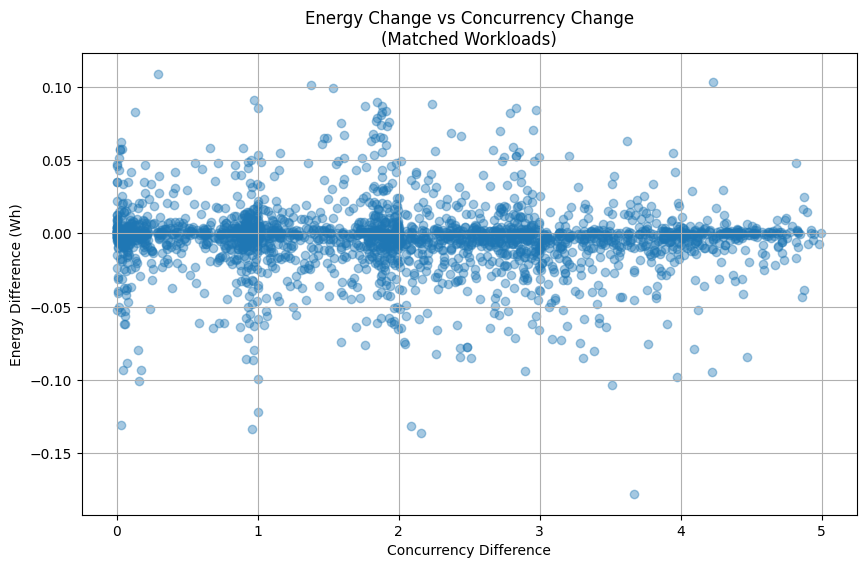

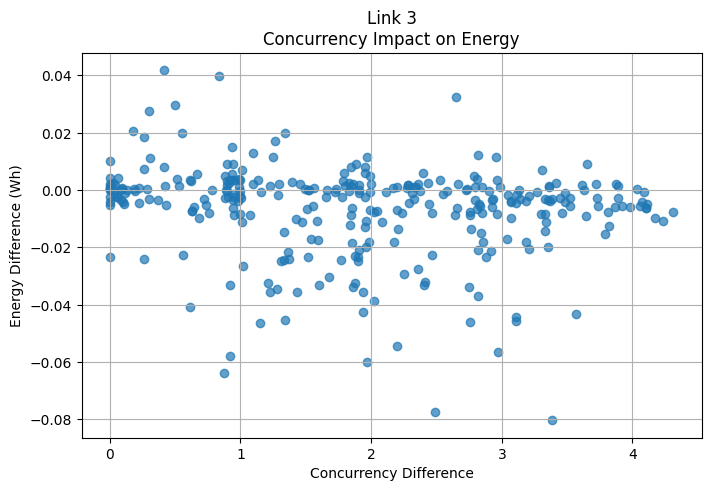

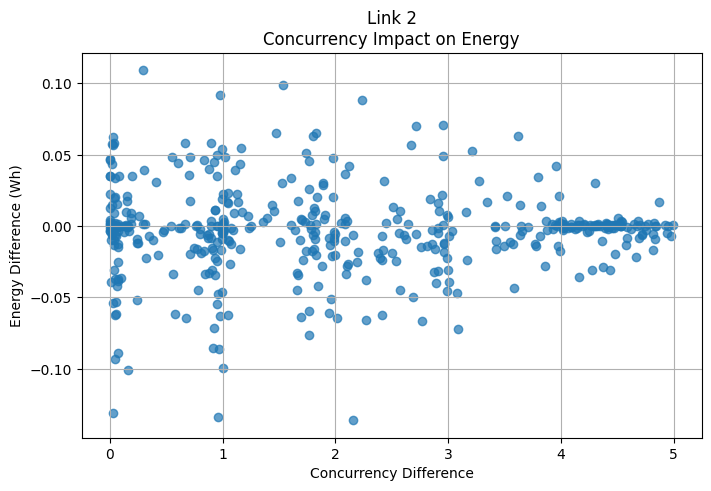

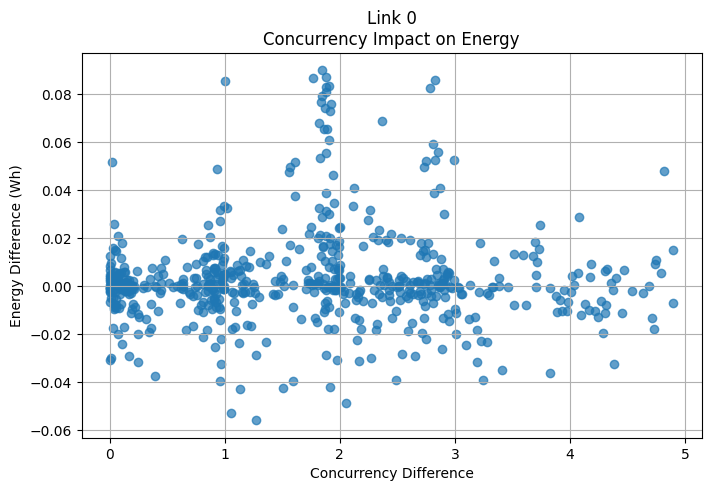

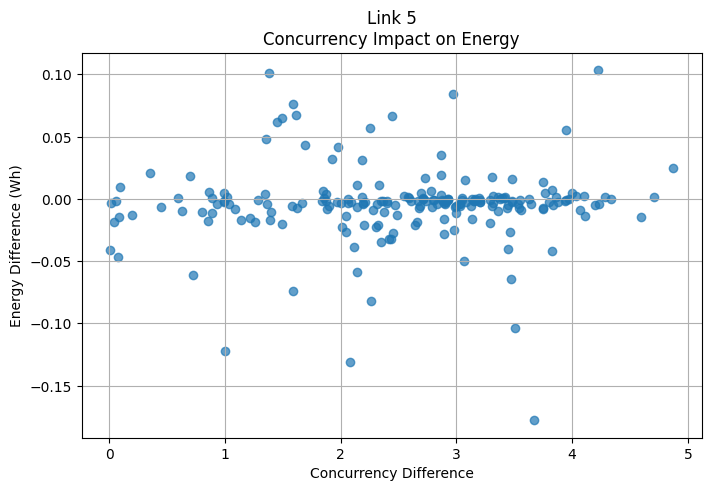

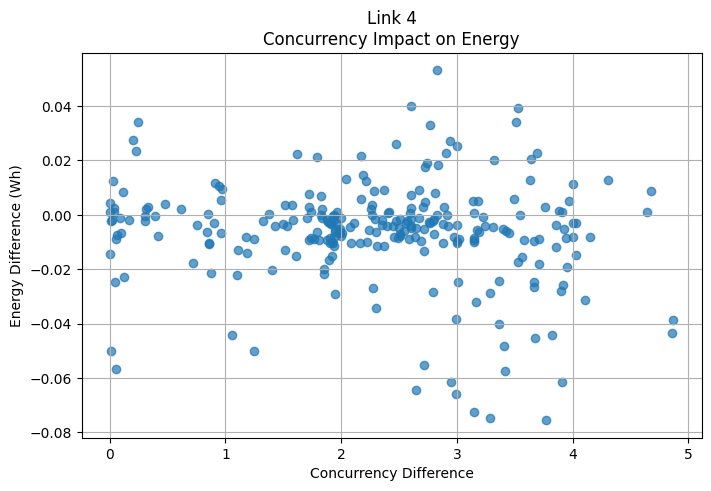

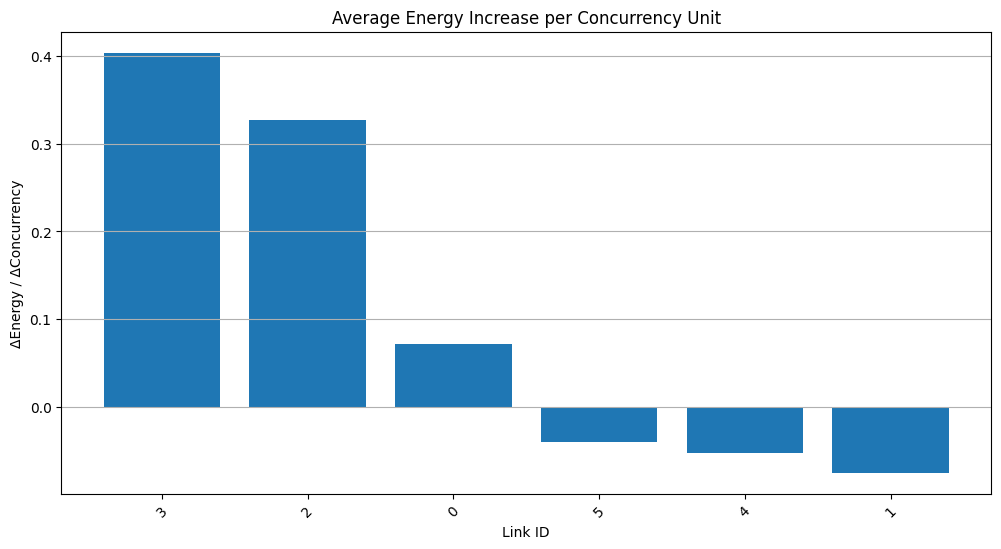


========== SUMMARY ==========

Pairs analysed: 2377
Links analysed: 6

Highest sensitivity link:
link_id                            3.000000
avg_energy_per_concurrency         0.403964
median_energy_per_concurrency     -0.001398
num_pairs                        311.000000
avg_energy_diff                   -0.006764
median_energy_diff                -0.002888
avg_concurrency_diff               1.891165
max_concurrency_diff               4.313630
Name: 3, dtype: float64


In [72]:
# =========================================================
# PER-LINK CONCURRENCY vs ENERGY ANALYSIS
# =========================================================
#
# GOAL
# ----
# For each link:
#
#   Keep workload approximately fixed
#       (data_amount_mb + bandwidth_req_mbps)
#
#   Observe how energy changes as
#       effective_concurrency changes.
#
# OUTPUT
# ------
# 1. Link summary table
# 2. Per-link concurrency sensitivity metric
# 3. Top most concurrency-sensitive links
# 4. Individual plots for selected links
#
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1. CLEAN DATA
# =========================================================

df_tmp = df_qos.copy()

df_tmp = df_tmp[
    df_tmp["total_energy_Wh"] > 0
].copy()

print("\n========== DATASET ==========\n")
print("Rows:", len(df_tmp))

# =========================================================
# 2. WORKLOAD BINNING
# =========================================================
#
# Same workload ≈ same bin
#
# =========================================================

DATA_BIN = 1.0      # MB
BW_BIN = 0.1        # Mbps

df_tmp["data_bin"] = (
    df_tmp["data_amount_mb"] / DATA_BIN
).round()

df_tmp["bw_bin"] = (
    df_tmp["bandwidth_req_mbps"] / BW_BIN
).round()

# =========================================================
# 3. BUILD PER-LINK PAIRS
# =========================================================

groups = df_tmp.groupby(
    ["link_id", "data_bin", "bw_bin"]
)

pairs = []

for key, g in groups:

    if len(g) < 2:
        continue

    # -----------------------------------------------------
    # Lowest concurrency sample
    # -----------------------------------------------------

    low = g.loc[
        g["effective_concurrency"].idxmin()
    ]

    # -----------------------------------------------------
    # Highest concurrency sample
    # -----------------------------------------------------

    high = g.loc[
        g["effective_concurrency"].idxmax()
    ]

    conc_diff = (
        high["effective_concurrency"]
        - low["effective_concurrency"]
    )

    if conc_diff <= 0:
        continue

    energy_diff = (
        high["total_energy_Wh"]
        - low["total_energy_Wh"]
    )

    pairs.append({

        "link_id": key[0],

        "concurrency_low":
            low["effective_concurrency"],

        "concurrency_high":
            high["effective_concurrency"],

        "concurrency_diff":
            conc_diff,

        "energy_low":
            low["total_energy_Wh"],

        "energy_high":
            high["total_energy_Wh"],

        "energy_diff":
            energy_diff,

        # energy increase per concurrency unit
        "energy_per_concurrency":
            energy_diff / conc_diff
    })

pairs_df = pd.DataFrame(pairs)

# =========================================================
# 4. LINK-LEVEL AGGREGATION
# =========================================================

link_stats = (
    pairs_df
    .groupby("link_id")
    .agg({

        "energy_per_concurrency": [
            "mean",
            "median",
            "count"
        ],

        "energy_diff": [
            "mean",
            "median"
        ],

        "concurrency_diff": [
            "mean",
            "max"
        ]
    })
)

link_stats.columns = [

    "avg_energy_per_concurrency",
    "median_energy_per_concurrency",
    "num_pairs",

    "avg_energy_diff",
    "median_energy_diff",

    "avg_concurrency_diff",
    "max_concurrency_diff"
]

link_stats = link_stats.reset_index()

# =========================================================
# 5. FILTER NOISY LINKS
# =========================================================
#
# Keep links with enough observations
#
# =========================================================

MIN_PAIRS = 5

link_stats = link_stats[
    link_stats["num_pairs"] >= MIN_PAIRS
].copy()

# =========================================================
# 6. SORT BY CONCURRENCY SENSITIVITY
# =========================================================

link_stats = link_stats.sort_values(
    "avg_energy_per_concurrency",
    ascending=False
)

print("\n========== MOST CONCURRENCY-SENSITIVE LINKS ==========\n")

print(
    link_stats.head(20)
)

# =========================================================
# 7. GLOBAL SCATTER
# =========================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    pairs_df["concurrency_diff"],
    pairs_df["energy_diff"],
    alpha=0.4
)

plt.xlabel("Concurrency Difference")
plt.ylabel("Energy Difference (Wh)")
plt.title(
    "Energy Change vs Concurrency Change\n"
    "(Matched Workloads)"
)

plt.grid(True)

plt.show()

# =========================================================
# 8. TOP LINKS VISUALIZATION
# =========================================================

TOP_K = 5

top_links = (
    link_stats["link_id"]
    .head(TOP_K)
    .tolist()
)

for link in top_links:

    link_pairs = pairs_df[
        pairs_df["link_id"] == link
    ]

    plt.figure(figsize=(8, 5))

    plt.scatter(
        link_pairs["concurrency_diff"],
        link_pairs["energy_diff"],
        alpha=0.7
    )

    plt.title(
        f"Link {link}\n"
        f"Concurrency Impact on Energy"
    )

    plt.xlabel(
        "Concurrency Difference"
    )

    plt.ylabel(
        "Energy Difference (Wh)"
    )

    plt.grid(True)

    plt.show()

# =========================================================
# 9. OPTIONAL BAR CHART
# =========================================================

TOP_N = 15

plot_df = link_stats.head(TOP_N)

plt.figure(figsize=(12, 6))

plt.bar(
    plot_df["link_id"].astype(str),
    plot_df["avg_energy_per_concurrency"]
)

plt.title(
    "Average Energy Increase per "
    "Concurrency Unit"
)

plt.xlabel("Link ID")
plt.ylabel("ΔEnergy / ΔConcurrency")

plt.xticks(rotation=45)

plt.grid(True, axis="y")

plt.show()

# =========================================================
# 10. SUMMARY
# =========================================================

print("\n========== SUMMARY ==========\n")

print(
    "Pairs analysed:",
    len(pairs_df)
)

print(
    "Links analysed:",
    len(link_stats)
)

print(
    "\nHighest sensitivity link:"
)

print(
    link_stats.iloc[0]
)

In [170]:
print(df_clean["link_id"].unique().tolist())

count0 = (df_clean["link_id"] == 0).sum()
count1 = (df_clean["link_id"] == 1).sum()
count2 = (df_clean["link_id"] == 2).sum()
count3 = (df_clean["link_id"] == 3).sum()
count4 = (df_clean["link_id"] == 4).sum()
count5 = (df_clean["link_id"] == 5).sum()
count6 = (df_clean["link_id"] == 6).sum()
count7 = (df_clean["link_id"] == 7).sum()

print(f"Number of entries with value 0: {count0}")
print(f"Number of entries with value 1: {count1}")
print(f"Number of entries with value 2: {count2}")
print(f"Number of entries with value 3: {count3}")
print(f"Number of entries with value 4: {count4}")

print(f"Number of entries with value 5: {count5}")
print(f"Number of entries with value 6: {count6}")
print(f"Number of entries with value 7: {count7}")


[2, 5, 6, 1, 3, 4]
Number of entries with value 0: 0
Number of entries with value 1: 2952
Number of entries with value 2: 4281
Number of entries with value 3: 2751
Number of entries with value 4: 3465
Number of entries with value 5: 4107
Number of entries with value 6: 3888
Number of entries with value 7: 0



========== DEBUG START ==========

Total rows: 21561
Unique links: 6
Link IDs: [2 5 6 1 3 4]

Columns: ['time', 'MB', 'bandwidth_req_mbps', 'data_amount_mb', 'dst_node', 'duration_s', 'exec_unit_id', 'jitter_ms', 'packet_loss_percent', 'src_node', 'throughput_mbps', 'total_energy_Wh', 'total_rx_Wh', 'total_tx_Wh', 'end_time', 'hour', 'day_of_week', 'is_weekend', 'month', 'workload_date', 'hour_sin', 'hour_cos', 'peak_concurrency', 'overlap_seconds_total', 'effective_concurrency', 'execution_failed', 'throughput_imputed', 'link_id', 'throughput_efficiency', 'energy_per_mb', 'energy_efficiency', 'conc_bin', 'data_bin', 'bw_bin']

Throughput stats:
count    21561.000000
mean         0.738984
std          0.282532
min          0.060598
25%          0.487500
50%          0.804166
75%          1.024999
max          1.054545
Name: throughput_efficiency, dtype: float64

NaN throughput count: 0

Filtered imputed rows: 21561 -> 21561

Number of time groups: 21561

Concurrency distribution:
coun

In [25]:
df_clean.columns

Index(['time', 'MB', 'bandwidth_req_mbps', 'data_amount_mb', 'dst_node',
       'duration_s', 'exec_unit_id', 'jitter_ms', 'packet_loss_percent',
       'src_node', 'throughput_mbps', 'total_energy_Wh', 'total_rx_Wh',
       'total_tx_Wh', 'end_time', 'hour', 'day_of_week', 'is_weekend', 'month',
       'workload_date', 'hour_sin', 'hour_cos', 'peak_concurrency',
       'overlap_seconds_total', 'effective_concurrency', 'execution_failed',
       'throughput_imputed', 'link_id', 'throughput_efficiency',
       'energy_per_mb', 'energy_efficiency', 'conc_bin', 'data_bin', 'bw_bin'],
      dtype='str')

In [1]:
import sklearn
print(sklearn.__version__)

1.8.0


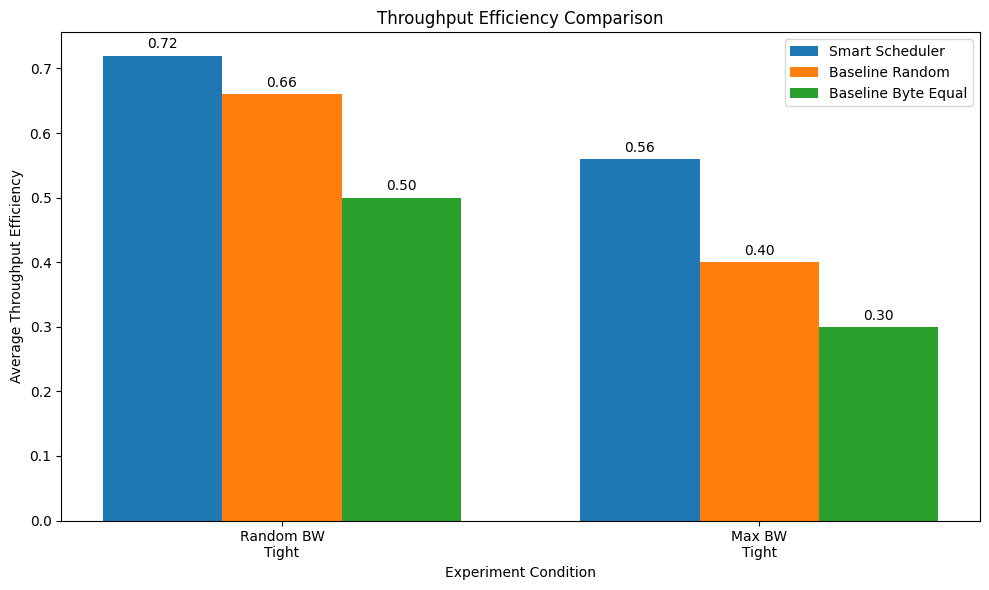

In [23]:

import matplotlib.pyplot as plt
import numpy as np

# =========================================================
# THROUGHPUT EFFICIENCY COMPARISON PLOTS
# =========================================================
# Replace the placeholder values with your real results.
#
# Suggested metric:
# throughput_efficiency =
# achieved_throughput / requested_bandwidth
#
# Example:
# 0.92 = 92% efficiency
# =========================================================

# ---------------------------------------------------------
# CONDITIONS
# ---------------------------------------------------------
conditions = [
    "Random BW\nTight",
    "Max BW\nTight",
]

# ---------------------------------------------------------
# OUR SCHEDULER
# ---------------------------------------------------------
scheduler_values = [
    0.72,  # replace
    0.56
]

# ---------------------------------------------------------
# BASELINE 1: RANDOM
# ---------------------------------------------------------
random_values = [
    0.66,
    0.40
]

# ---------------------------------------------------------
# BASELINE 2: ROUND ROBIN / BYTE EQUAL
# ---------------------------------------------------------
round_robin_values = [
    0.5,
    0.3
]

# =========================================================
# PLOT CONFIGURATION
# =========================================================
x = np.arange(len(conditions))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

# ---------------------------------------------------------
# BARS
# ---------------------------------------------------------
bars1 = ax.bar(
    x - width,
    scheduler_values,
    width,
    label="Smart Scheduler"
)

bars2 = ax.bar(
    x,
    random_values,
    width,
    label="Baseline Random"
)

bars3 = ax.bar(
    x + width,
    round_robin_values,
    width,
    label="Baseline Byte Equal"
)

# =========================================================
# LABELS
# =========================================================
ax.set_ylabel("Average Throughput Efficiency")
ax.set_xlabel("Experiment Condition")
ax.set_title("Throughput Efficiency Comparison")
ax.set_xticks(x)
ax.set_xticklabels(conditions)

ax.legend()

# ---------------------------------------------------------
# OPTIONAL VALUE LABELS
# ---------------------------------------------------------
def add_labels(bars):

    for bar in bars:

        height = bar.get_height()

        ax.annotate(
            f"{height:.2f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),
            textcoords="offset points",
            ha='center',
            va='bottom'
        )

add_labels(bars1)
add_labels(bars2)
add_labels(bars3)

# =========================================================
# SAVE + SHOW
# =========================================================
plt.tight_layout()

plt.savefig(
    "throughput_efficiency_comparison.png",
    dpi=300
)

plt.show()

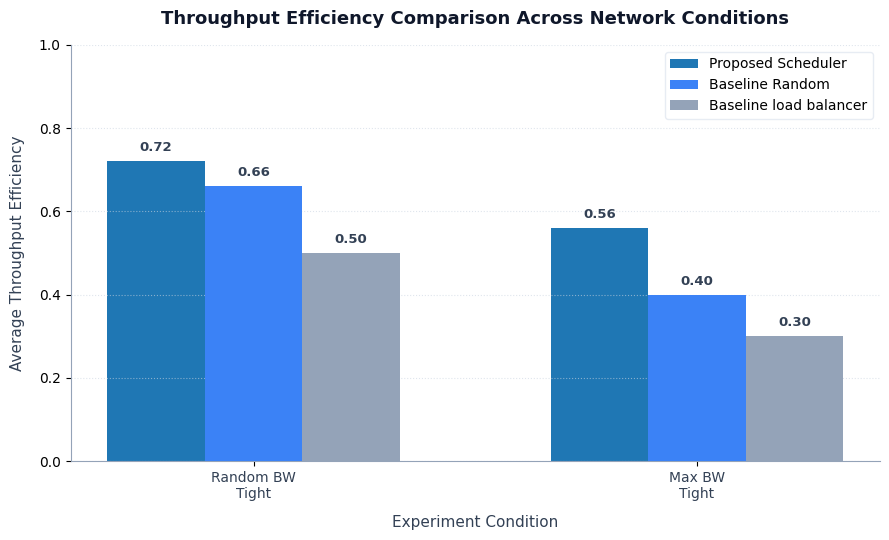

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# =========================================================
# THROUGHPUT EFFICIENCY COMPARISON PLOTS
# =========================================================

# ---------------------------------------------------------
# EXPERIMENT DATA
# ---------------------------------------------------------
conditions = [
    "Random BW\nTight",
    "Max BW\nTight",
]

scheduler_values = [0.72, 0.56]
random_values = [0.66, 0.40]
round_robin_values = [0.5, 0.3]

# =========================================================
# PLOT CONFIGURATION
# =========================================================
x = np.arange(len(conditions))
width = 0.22  # Slightly narrower bars for cleaner separation

fig, ax = plt.subplots(figsize=(9, 5.5))

# ---------------------------------------------------------
# STYLING (Colors, Grid, Spines)
# ---------------------------------------------------------
# Soft professional color scheme
colors = {
    'scheduler': '#0F172A',   # Deep Slate Blue (Primary Focus)
    'random': '#3B82F6',      # Vibrant Blue (Baseline 1)
    'round_robin': '#94A3B8'  # Muted Slate Gray (Baseline 2)
}

# Soft vertical gridlines placed strictly behind the data bars
ax.grid(axis='y', linestyle=':', alpha=0.6, color='#CBD5E1', zorder=0)

# Remove top and right borders (spines) for a clean modern finish
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color('#94A3B8')

# ---------------------------------------------------------
# DATA REPRESENTATION (Bars)
# ---------------------------------------------------------
# zorder=3 forces bars to render cleanly in front of the background grid
bars1 = ax.bar(
    x - width, scheduler_values, width, 
    label="Proposed Scheduler"
)

bars2 = ax.bar(
    x, random_values, width, 
    label="Baseline Random", color=colors['random'], zorder=3
)

bars3 = ax.bar(
    x + width, round_robin_values, width, 
    label="Baseline load balancer", color=colors['round_robin'], zorder=3
)

# =========================================================
# LABELS & METADATA
# =========================================================
ax.set_ylabel("Average Throughput Efficiency", fontsize=11, fontweight='medium', labelpad=10, color='#334155')
ax.set_xlabel("Experiment Condition", fontsize=11, fontweight='medium', labelpad=10, color='#334155')
ax.set_title("Throughput Efficiency Comparison Across Network Conditions", fontsize=13, fontweight='bold', pad=15, color='#0F172A')

ax.set_xticks(x)
ax.set_xticklabels(conditions, fontsize=10, color='#334155')
ax.set_ylim(0, 1.0)  # Efficiency metrics safely bound between 0.0 and 1.0

# Clean frame legend positioning
ax.legend(loc='upper right', frameon=True, facecolor='#FFFFFF', edgecolor='#E2E8F0', fontsize=10)

# ---------------------------------------------------------
# DATA LABELS (Values on top of bars)
# ---------------------------------------------------------
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.2f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),  # 5 points vertical padding above bar
            textcoords="offset points",
            ha='center', va='bottom',
            fontsize=9.5, fontweight='semibold', color='#334155'
        )

add_labels(bars1)
add_labels(bars2)
add_labels(bars3)

# =========================================================
# SAVE FILE
# =========================================================
plt.tight_layout()

# bbox_inches='tight' prevents axis labels from being cut off during saving
plt.savefig(
    "throughput_efficiency_comparison.png",
    dpi=300,
    bbox_inches='tight'
)

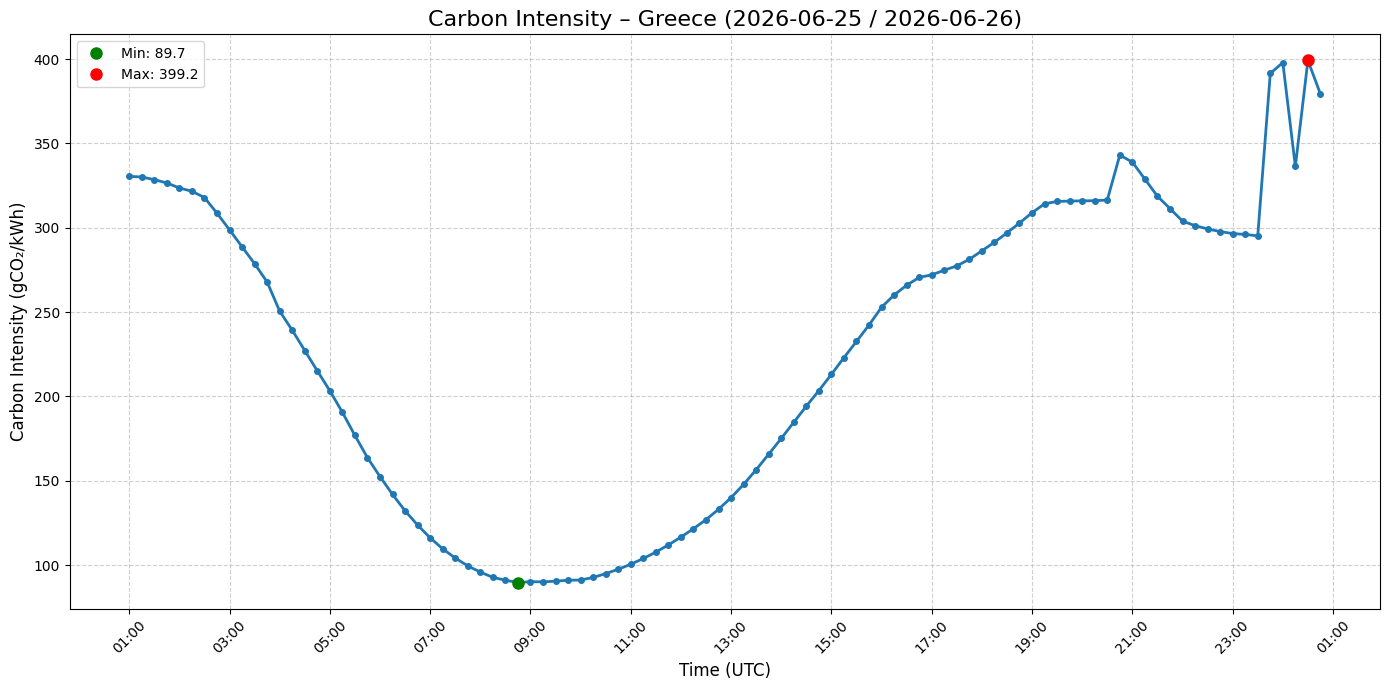

In [29]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime

# The carbon intensity data (as a Python list of dicts)
data = [
    {
        "footprint_type": "carbon",
        "scope": "life-cycle",
        "zone": "GR",
        "unit": "gCO2/kWh",
        "coverage": "global",
        "series": [
            {
                "valid": True,
                "zone_status": "preview",
                "values": [
                    ["2026-06-25T01:00:00Z", 330.52],
                    ["2026-06-25T01:15:00Z", 330.13],
                    ["2026-06-25T01:30:00Z", 328.56],
                    ["2026-06-25T01:45:00Z", 326.59],
                    ["2026-06-25T02:00:00Z", 323.63],
                    ["2026-06-25T02:15:00Z", 321.68],
                    ["2026-06-25T02:30:00Z", 317.95],
                    ["2026-06-25T02:45:00Z", 308.67],
                    ["2026-06-25T03:00:00Z", 298.82],
                    ["2026-06-25T03:15:00Z", 288.75],
                    ["2026-06-25T03:30:00Z", 278.72],
                    ["2026-06-25T03:45:00Z", 267.86],
                    ["2026-06-25T04:00:00Z", 250.61],
                    ["2026-06-25T04:15:00Z", 239.29],
                    ["2026-06-25T04:30:00Z", 227.25],
                    ["2026-06-25T04:45:00Z", 215.2],
                    ["2026-06-25T05:00:00Z", 203.41],
                    ["2026-06-25T05:15:00Z", 190.62],
                    ["2026-06-25T05:30:00Z", 176.89],
                    ["2026-06-25T05:45:00Z", 163.72],
                    ["2026-06-25T06:00:00Z", 152.5],
                    ["2026-06-25T06:15:00Z", 141.92],
                    ["2026-06-25T06:30:00Z", 132.23],
                    ["2026-06-25T06:45:00Z", 123.75],
                    ["2026-06-25T07:00:00Z", 116.2],
                    ["2026-06-25T07:15:00Z", 109.66],
                    ["2026-06-25T07:30:00Z", 104.23],
                    ["2026-06-25T07:45:00Z", 99.57],
                    ["2026-06-25T08:00:00Z", 95.88],
                    ["2026-06-25T08:15:00Z", 92.75],
                    ["2026-06-25T08:30:00Z", 91.07],
                    ["2026-06-25T08:45:00Z", 89.7],
                    ["2026-06-25T09:00:00Z", 90.19],
                    ["2026-06-25T09:15:00Z", 90.1],
                    ["2026-06-25T09:30:00Z", 90.51],
                    ["2026-06-25T09:45:00Z", 91.06],
                    ["2026-06-25T10:00:00Z", 91.17],
                    ["2026-06-25T10:15:00Z", 92.73],
                    ["2026-06-25T10:30:00Z", 94.96],
                    ["2026-06-25T10:45:00Z", 97.57],
                    ["2026-06-25T11:00:00Z", 100.53],
                    ["2026-06-25T11:15:00Z", 103.96],
                    ["2026-06-25T11:30:00Z", 107.71],
                    ["2026-06-25T11:45:00Z", 112.01],
                    ["2026-06-25T12:00:00Z", 116.63],
                    ["2026-06-25T12:15:00Z", 121.63],
                    ["2026-06-25T12:30:00Z", 126.97],
                    ["2026-06-25T12:45:00Z", 133.12],
                    ["2026-06-25T13:00:00Z", 140.05],
                    ["2026-06-25T13:15:00Z", 147.9],
                    ["2026-06-25T13:30:00Z", 156.58],
                    ["2026-06-25T13:45:00Z", 165.79],
                    ["2026-06-25T14:00:00Z", 175.16],
                    ["2026-06-25T14:15:00Z", 184.71],
                    ["2026-06-25T14:30:00Z", 194.25],
                    ["2026-06-25T14:45:00Z", 203.48],
                    ["2026-06-25T15:00:00Z", 213.13],
                    ["2026-06-25T15:15:00Z", 223.03],
                    ["2026-06-25T15:30:00Z", 232.65],
                    ["2026-06-25T15:45:00Z", 242.38],
                    ["2026-06-25T16:00:00Z", 252.89],
                    ["2026-06-25T16:15:00Z", 260.16],
                    ["2026-06-25T16:30:00Z", 265.95],
                    ["2026-06-25T16:45:00Z", 270.6],
                    ["2026-06-25T17:00:00Z", 272.12],
                    ["2026-06-25T17:15:00Z", 274.86],
                    ["2026-06-25T17:30:00Z", 277.44],
                    ["2026-06-25T17:45:00Z", 281.32],
                    ["2026-06-25T18:00:00Z", 286.36],
                    ["2026-06-25T18:15:00Z", 291.44],
                    ["2026-06-25T18:30:00Z", 297.0],
                    ["2026-06-25T18:45:00Z", 302.85],
                    ["2026-06-25T19:00:00Z", 308.95],
                    ["2026-06-25T19:15:00Z", 314.24],
                    ["2026-06-25T19:30:00Z", 315.65],
                    ["2026-06-25T19:45:00Z", 315.84],
                    ["2026-06-25T20:00:00Z", 316.01],
                    ["2026-06-25T20:15:00Z", 316.07],
                    ["2026-06-25T20:30:00Z", 316.49],
                    ["2026-06-25T20:45:00Z", 343.14],
                    ["2026-06-25T21:00:00Z", 338.95],
                    ["2026-06-25T21:15:00Z", 328.87],
                    ["2026-06-25T21:30:00Z", 318.76],
                    ["2026-06-25T21:45:00Z", 311.39],
                    ["2026-06-25T22:00:00Z", 303.99],
                    ["2026-06-25T22:15:00Z", 301.27],
                    ["2026-06-25T22:30:00Z", 299.35],
                    ["2026-06-25T22:45:00Z", 297.77],
                    ["2026-06-25T23:00:00Z", 296.6],
                    ["2026-06-25T23:15:00Z", 296.07],
                    ["2026-06-25T23:30:00Z", 295.24],
                    ["2026-06-25T23:45:00Z", 391.55],
                    ["2026-06-26T00:00:00Z", 397.97],
                    ["2026-06-26T00:30:00Z", 399.24],
                    ["2026-06-26T00:45:00Z", 379.32]
                ]
            },
            {
                "valid": True,
                "zone_status": "complete",
                "values": [
                    ["2026-06-26T00:15:00Z", 336.36]
                ]
            }
        ]
    }
]


def plot_carbon_intensity(data):
    """
    Merge all series and plot carbon intensity over time.
    """
    # Dictionary to hold timestamp (datetime) -> value
    time_value = {}

    # Iterate over all series (preview + complete)
    for series in data[0]['series']:
        for ts_str, val in series['values']:
            # Convert ISO timestamp with 'Z' to timezone-aware datetime (UTC)
            dt = datetime.fromisoformat(ts_str.replace('Z', '+00:00'))
            time_value[dt] = val

    # Sort by time
    sorted_items = sorted(time_value.items())
    times = [item[0] for item in sorted_items]
    values = [item[1] for item in sorted_items]

    # Determine date range for title
    start_date = times[0].strftime('%Y-%m-%d')
    end_date = times[-1].strftime('%Y-%m-%d')
    if start_date == end_date:
        date_str = start_date
    else:
        date_str = f"{start_date} / {end_date}"

    # Create the plot
    fig, ax = plt.subplots(figsize=(14, 7))
    ax.plot(times, values, marker='o', linestyle='-', linewidth=2, markersize=4)

    # Labels and title
    ax.set_title(f'Carbon Intensity – Greece ({date_str})', fontsize=16)
    ax.set_xlabel('Time (UTC)', fontsize=12)
    ax.set_ylabel('Carbon Intensity (gCO₂/kWh)', fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.6)

    # Format x-axis: show hours and minutes, major ticks every 2 hours
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
    plt.xticks(rotation=45)

    # Highlight min and max
    min_idx = values.index(min(values))
    max_idx = values.index(max(values))
    ax.plot(times[min_idx], values[min_idx], 'go', markersize=8, label=f'Min: {values[min_idx]:.1f}')
    ax.plot(times[max_idx], values[max_idx], 'ro', markersize=8, label=f'Max: {values[max_idx]:.1f}')
    ax.legend()

    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    plot_carbon_intensity(data)

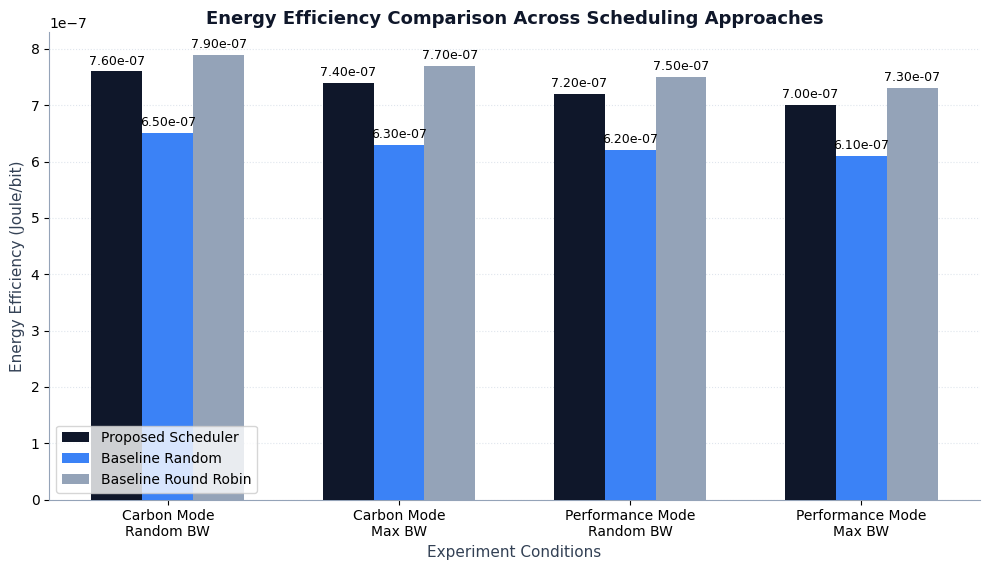

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# =========================================================
# ENERGY EFFICIENCY COMPARISON PLOT
# =========================================================

# ---------------------------------------------------------
# EXPERIMENT CONDITIONS (edit freely)
# ---------------------------------------------------------
conditions = [
    "Carbon Mode\nRandom BW",
    "Carbon Mode\nMax BW",
    "Performance Mode\nRandom BW",
    "Performance Mode\nMax BW"
]

# ---------------------------------------------------------
# PLACEHOLDER DATA (replace with your measured values)
# ---------------------------------------------------------
scheduler_energy_eff = [7.6e-7, 7.4e-7, 7.2e-7, 7.0e-7]
random_energy_eff    = [6.5e-7, 6.3e-7, 6.2e-7, 6.1e-7]
round_robin_energy   = [7.9e-7, 7.7e-7, 7.5e-7, 7.3e-7]

# (Optional) total energy if you want second plot later
scheduler_total_energy = [3.42, 3.50, 3.10, 3.20]
random_total_energy    = [2.90, 3.00, 2.85, 2.95]
round_robin_total_energy = [3.51, 3.60, 3.40, 3.45]

# =========================================================
# PLOT SETUP
# =========================================================
x = np.arange(len(conditions))
width = 0.22

fig, ax = plt.subplots(figsize=(10, 5.8))

# ---------------------------------------------------------
# STYLE
# ---------------------------------------------------------
colors = {
    "scheduler": "#0F172A",
    "random": "#3B82F6",
    "round_robin": "#94A3B8"
}

ax.grid(axis='y', linestyle=':', alpha=0.6, color='#CBD5E1', zorder=0)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color('#94A3B8')

# =========================================================
# BARS
# =========================================================
bars1 = ax.bar(
    x - width,
    scheduler_energy_eff,
    width,
    label="Proposed Scheduler",
    color=colors["scheduler"],
    zorder=3
)

bars2 = ax.bar(
    x,
    random_energy_eff,
    width,
    label="Baseline Random",
    color=colors["random"],
    zorder=3
)

bars3 = ax.bar(
    x + width,
    round_robin_energy,
    width,
    label="Baseline Round Robin",
    color=colors["round_robin"],
    zorder=3
)

# =========================================================
# LABELS
# =========================================================
ax.set_ylabel("Energy Efficiency (Joule/bit)", fontsize=11, color='#334155')
ax.set_xlabel("Experiment Conditions", fontsize=11, color='#334155')
ax.set_title("Energy Efficiency Comparison Across Scheduling Approaches",
             fontsize=13, fontweight='bold', color='#0F172A')

ax.set_xticks(x)
ax.set_xticklabels(conditions, fontsize=10)
ax.legend()

# =========================================================
# VALUE ANNOTATIONS
# =========================================================
def add_labels(bars):
    for b in bars:
        h = b.get_height()
        ax.annotate(
            f"{h:.2e}",
            xy=(b.get_x() + b.get_width()/2, h),
            xytext=(0, 5),
            textcoords="offset points",
            ha='center',
            fontsize=9
        )

add_labels(bars1)
add_labels(bars2)
add_labels(bars3)

# =========================================================
# SAVE FIGURE
# =========================================================
plt.tight_layout()
plt.savefig(
    "energy_efficiency_comparison.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()